# Makine Öğrenmesi ile Orman Yangını Duyarlılığı Analizi
## Muğla'da Yangın ve Yangın Olmayan Noktalar Üzerine On Bir Algoritmayla Karşılaştırmalı Bir Uygulama

---

Bu dosya, kitaptaki **bütün çözümlemeleri tek bir defterde** toplar. Her bölüm,
kitaptaki ilgili bölümün sayısal omurgasını oluşturur ve baştan sona çalıştırılabilir.

**Not:** Grafik ve tablo çıktıları deftere **gömülü** olarak gelmektedir; yani
kodu çalıştırmadan da bütün sonuçları görebilirsiniz. Dilerseniz değerleri
bizzat doğrulamak için defteri baştan çalıştırabilirsiniz.

**Nasıl çalıştırılır?**

1. Bu dosyayı Jupyter Notebook / JupyterLab / VS Code ile açın.
2. Menüden **Cell → Run All** (Tümünü Çalıştır) seçin.
3. Bütün bölümler sırayla çalışır; şekiller `sekiller/`, sonuçlar `sonuclar/` klasörüne yazılır.

**Bölümler**

- BÖLÜM 1 — Veri Seti ve Keşifsel Veri Analizi
- BÖLÜM 2 — Lojistik Regresyon
- BÖLÜM 3 — Lineer Regresyon
- BÖLÜM 4 — K-En Yakın Komşu (KNN)
- BÖLÜM 5 — Destek Vektör Makineleri (SVM)
- BÖLÜM 6 — Karar Ağaçları
- BÖLÜM 7 — Rastgele Orman
- BÖLÜM 8 — Naive Bayes
- BÖLÜM 9 — Gradyan Artırma (GBM)
- BÖLÜM 10 — XGBoost
- BÖLÜM 11 — CatBoost
- BÖLÜM 12 — LightGBM
- BÖLÜM 13 — Karşılaştırma ve Genel Değerlendirme

---

> **Veri:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0); Muğla ili,
> 2015–2024 yangın kayıtları; bir satır = bir örnek nokta (yangın olan / olmayan).
> **Hedef:** yangın duyarlılık skoru (regresyon) ve Yangın / Yangın Yok (sınıflandırma).
> **Tekrar üretilebilirlik:** sınıfa göre katmanlı %80/%20 bölünme ve bütün rastgeleliklerde `random_state = 42`.

## Ortak Kurulum

Aşağıdaki hücre, bütün bölümlerde kullanılan ortak modülü (`ortak.py`) yükler.
Bu hücre **bir kez** çalıştırılır; sonraki bütün bölümler onu kullanır.

In [1]:
# Ortak modül ve standart kütüphaneler
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print('Ortak modül yüklendi.')
print('Özellikler :', o.OZELLIKLER)
print('Sınıflar   :', o.SINIF_ETIKETLERI)

Ortak modül yüklendi.
Özellikler : ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Sınıflar   : ['Yangın Yok', 'Yangın']



---

# BÖLÜM 1 — Veri Seti ve Keşifsel Veri Analizi

*Bu bölümün kaynak defteri:* `00_veri_kesfi.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Bu notebook, kitaptaki bütün makine öğrenmesi uygulamalarının temelini oluşturan
veri setini tanıtır. İncelemenin her adımı, kitap metnindeki sayıların doğrudan
kaynağıdır; hesaplanan değerler en sonda `sonuclar/_veri_ozeti.json` dosyasına yazılır.

In [2]:
import ortak as o
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = o.veri_yukle()
EK = {}          # kitap metnine aktarılacak ek sayılar
print("Nokta sayısı        :", len(df))
print("Özellikler (16)     :", o.OZELLIKLER)
print("İklim grubu sayısı  :", df[o.GRUP].nunique())
df[["Nokta_No", "Yangin", "Baki", "Arazi", "NDVI", "Egim", "Yukseklik", "Sicaklik",
    "Yagis", "Ruzgar_Hizi", "Yol_Uzaklik", "Yerlesim_Uzaklik", "Sinif"]].head(8)

6410 nokta · yangın 3144 · yangın yok 3266
Nokta sayısı        : 6410
Özellikler (16)     : ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
İklim grubu sayısı  : 25


,Nokta_No,Yangin,Baki,Arazi,NDVI,Egim,Yukseklik,Sicaklik,Yagis,Ruzgar_Hizi,Yol_Uzaklik,Yerlesim_Uzaklik,Sinif
0,1,1,Düz,Tarım,0.274741,0.000000,16.000000,19.13671,101.10270,1.985137,72.404543,341.064792,Yangın
1,2,1,Düz,Tarım,0.097535,0.000000,328.982200,16.68583,49.10944,1.688260,214.293189,3204.075548,Yangın
2,3,1,Düz,Tarım,0.118961,0.000000,6.000000,17.82831,52.20567,1.716142,74.094309,408.695148,Yangın
3,4,1,Doğu,Yerleşim,0.100288,0.372233,3.000000,18.92697,88.27003,2.888625,30.619806,83.387360,Yangın
4,5,1,Kuzeybatı,Tarım,0.322840,0.372233,6.030597,19.04383,87.37311,2.215718,133.770926,248.464281,Yangın
5,6,1,Kuzey,Tarım,0.239704,0.372233,5.905493,19.02674,73.91023,2.153053,347.849212,479.849412,Yangın
6,7,1,Kuzey,Tarım,0.137894,0.372233,18.665390,19.36422,98.27899,2.269851,29.421317,3.256806,Yangın
7,8,1,Güneybatı,Orman,0.128258,0.372233,145.328000,17.87529,61.93587,1.426053,149.581803,1173.718254,Yangın


### 1. Kaynağı ve Temizlik Adımlarını Doğrulama

Veri seti, Mendeley Data deposunda CC BY 4.0 lisansıyla yayımlanan **"Forest fire and
non-fire sample points with eleven conditioning factors for Muğla, Türkiye (2015–2024)"**
veri setidir (Eriş, 2026; doi:10.17632/mjz29dh3g8.1). Yangın kayıtları Muğla Orman Bölge
Müdürlüğü'ne aittir. Dosya, depo API'sinden indirilmiş ve SHA-256 özetiyle doğrulanmıştır
(`_builder/veri_indir.py`); temizlik adımları `_builder/veri_hazirla.py` dosyasındadır.
Aşağıdaki hücre, temizlik adımlarının sayısal dökümünü okur.

**Önemli bir kaynak sınırlılığı:** Veri setinde noktaların coğrafi koordinatları yoktur.
Bu nedenle gerçek mekânsal doğrulama yapılamaz; bunun yerine iklim yüzeylerinden türetilmiş
**sözde mekânsal gruplar** kullanılır (Bölüm 7).

In [3]:
with open(o.TEMIZLIK_YOLU, encoding="utf-8") as f:
    tem = json.load(f)
print(o.KAYNAK); print("doi:" + o.KAYNAK_DOI); print(o.KAYNAK_URL)
print()
print(f"Ham satır                          : {tem['ham_satir']} "
      f"(yangın {tem['ham_sinif']['yangin']}, yangın değil {tem['ham_sinif']['yangin_degil']})")
print(f"Ham özellik (etken) sayısı         : {tem['ham_ozellik_sayisi']}")
print(f"Ham dosya sınıfa göre sıralı mı?   : {'evet (önce bütün yangın noktaları)' if tem['ham_siralama_sinifa_gore'] else 'hayır'}")
print(f"Arazi örtüsü bilinmeyen (çıkarıldı): {tem['bilinmeyen_arazi_cikarilan']} satır")
print(f"Çelişkili etiket (çıkarıldı)       : {tem['celiskili_satir_cikarilan']} satır, {tem['celiskili_grup']} özellik grubu")
print(f"Yinelenen satır (çıkarıldı)        : {tem['yinelenen_satir_cikarilan']}")
print(f"Eksik değer                        : {tem['eksik_deger']}")
print(f"Çalışmaya giren nokta              : {tem['son_satir']} "
      f"(yangın {tem['son_sinif']['yangin']}, yangın yok {tem['son_sinif']['yangin_degil']})")
EK["temizlik"] = tem

Eriş, B. (2026). Forest fire and non-fire sample points with eleven conditioning factors for Muğla, Türkiye (2015–2024). Mendeley Data, V1
doi:10.17632/mjz29dh3g8.1
https://data.mendeley.com/datasets/mjz29dh3g8/1

Ham satır                          : 6746 (yangın 3373, yangın değil 3373)
Ham özellik (etken) sayısı         : 11
Ham dosya sınıfa göre sıralı mı?   : evet (önce bütün yangın noktaları)
Arazi örtüsü bilinmeyen (çıkarıldı): 3 satır
Çelişkili etiket (çıkarıldı)       : 214 satır, 104 özellik grubu
Yinelenen satır (çıkarıldı)        : 119
Eksik değer                        : 0
Çalışmaya giren nokta              : 6410 (yangın 3144, yangın yok 3266)


### 2. Hedef Değişken ve Arazi Örtüsü

Veri seti yangın noktaları ile yangın olmayan noktaları yaklaşık eşit sayıda içerir;
bu, yangın duyarlılığı çalışmalarındaki yaygın tasarımdır. Sınıf dengesi, doğruluk
(accuracy) ölçütünün yanıltıcı olmasını önler. Arazi örtüsü ise yangınların nerede
yoğunlaştığının ilk ipucunu verir: "orman yangını" kataloğu olmasına karşın yangın
noktalarının önemli bir kısmı tarım alanlarındadır.

Sinif
Yangın Yok    3266
Yangın        3144

                   Nokta  Yangin  Yangin_Orani
Arazi                                         
Yerleşim             140     122         0.871
Tarım               1510    1023         0.677
Orman               1795    1133         0.631
Çalılık ve Çayır    2674     838         0.313
Su ve Çıplak Alan    291      28         0.096


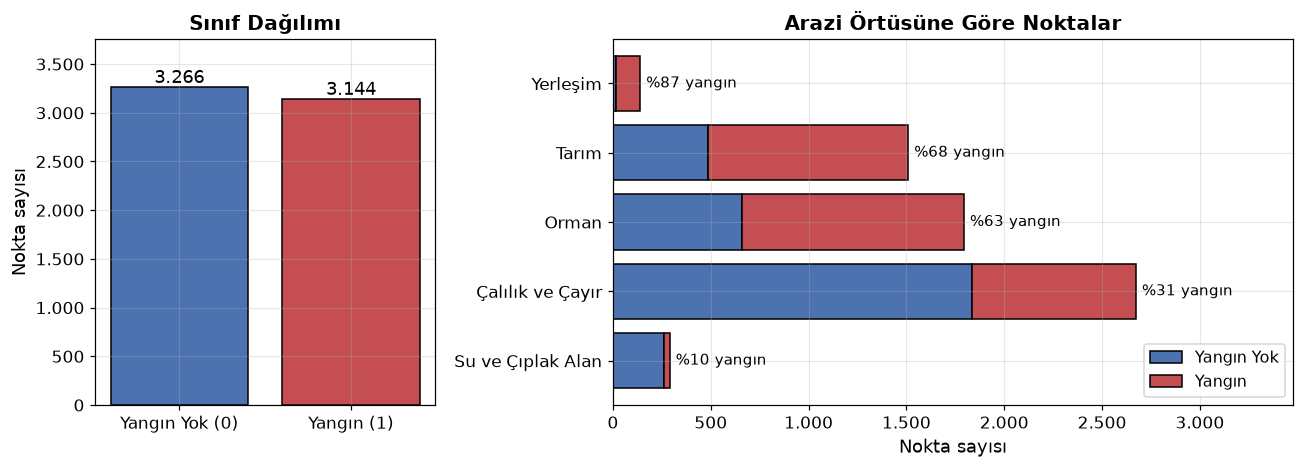

In [4]:
sayim = df["Sinif"].value_counts().reindex(o.SINIF_ETIKETLERI)
print(sayim.to_string())
print()
arazi = (df.groupby("Arazi").agg(Nokta=("Yangin", "size"), Yangin=("Yangin", "sum"),
                                 Yangin_Orani=("Yangin", "mean"))
           .sort_values("Yangin_Orani", ascending=False))
print(arazi.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.bar(o.SINIF_ACIKLAMA, sayim.values, color=["#4c72b0", "#c44e52"], edgecolor="k")
for i, v in enumerate(sayim.values):
    ax.text(i, v + 40, o.tam(v), ha="center")
ax.set_ylabel("Nokta sayısı")
ax.set_title("Sınıf Dağılımı")
ax.set_ylim(0, sayim.max() * 1.15)
ax = axes[1]
y = np.arange(len(arazi))
ax.barh(y, arazi["Nokta"] - arazi["Yangin"], color="#4c72b0", edgecolor="k", label="Yangın Yok")
ax.barh(y, arazi["Yangin"], left=arazi["Nokta"] - arazi["Yangin"], color="#c44e52", edgecolor="k", label="Yangın")
for i, (n, r) in enumerate(zip(arazi["Nokta"], arazi["Yangin_Orani"])):
    ax.text(n + 30, i, f"%{r * 100:.0f} yangın", va="center", fontsize=10)
ax.set_yticks(y)
ax.set_yticklabels(arazi.index)
ax.invert_yaxis()
ax.set_xlabel("Nokta sayısı")
ax.set_xlim(0, arazi["Nokta"].max() * 1.3)
ax.set_title("Arazi Örtüsüne Göre Noktalar")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_hedef_sinif.png"), bbox_inches="tight")
plt.show()
EK["arazi_tablo"] = {k: {"nokta": int(r.Nokta), "yangin": int(r.Yangin), "oran": float(r.Yangin_Orani)}
                     for k, r in arazi.iterrows()}

### 3. Tanımlayıcı İstatistikler

In [5]:
tanim = df[o.SAYISAL].describe().T
tanim["çarpıklık"] = df[o.SAYISAL].skew()
print(tanim.round(3).to_string())
EK["tanim"] = {c: {k: float(v) for k, v in tanim.loc[c].items()} for c in o.SAYISAL}

                   count      mean       std     min      25%       50%       75%        max  çarpıklık
Yukseklik         6410.0   751.161   653.854  -1.000  179.000   573.000  1241.974   2928.000      0.776
Egim              6410.0    14.644     9.337   0.000    7.152    13.521    20.840     66.943      0.637
Sicaklik          6410.0    17.330     2.292  11.120   16.025    17.699    19.060     21.892     -0.782
Yagis             6410.0    69.185    17.917  28.351   55.601    65.188    79.613    129.993      0.729
Ruzgar_Hizi       6410.0     2.181     0.767   0.827    1.792     1.951     2.339      7.683      3.195
NDVI              6410.0     0.181     0.087  -0.480    0.114     0.185     0.245      0.697     -0.030
Yol_Uzaklik       6410.0   670.267   895.086   0.048   87.578   319.582   885.194   7983.795      2.523
Yerlesim_Uzaklik  6410.0  3219.423  3344.285   0.000  975.603  2132.252  4066.075  18816.120      1.930
Akarsu_Uzaklik    6410.0   825.241   736.524   0.088  308.352   

### 4. Sayısal Etkenlerin Sınıflara Göre Dağılımı

Her etken için yangın noktaları ile yangın olmayan noktaların dağılımı karşılaştırılır.
İki dağılım ne kadar ayrışıyorsa etken o kadar bilgilendiricidir. Ayrışmanın büyüklüğü,
etkenin tek başına yangın noktalarını ne kadar iyi sıraladığını gösteren **tek değişkenli
AUC** ile de ölçülür (0,5 = hiç ayırt edemez, 1 = kusursuz ayırır; 0,5'in altındaki
değerler etkenin ters yönde çalıştığını gösterir).

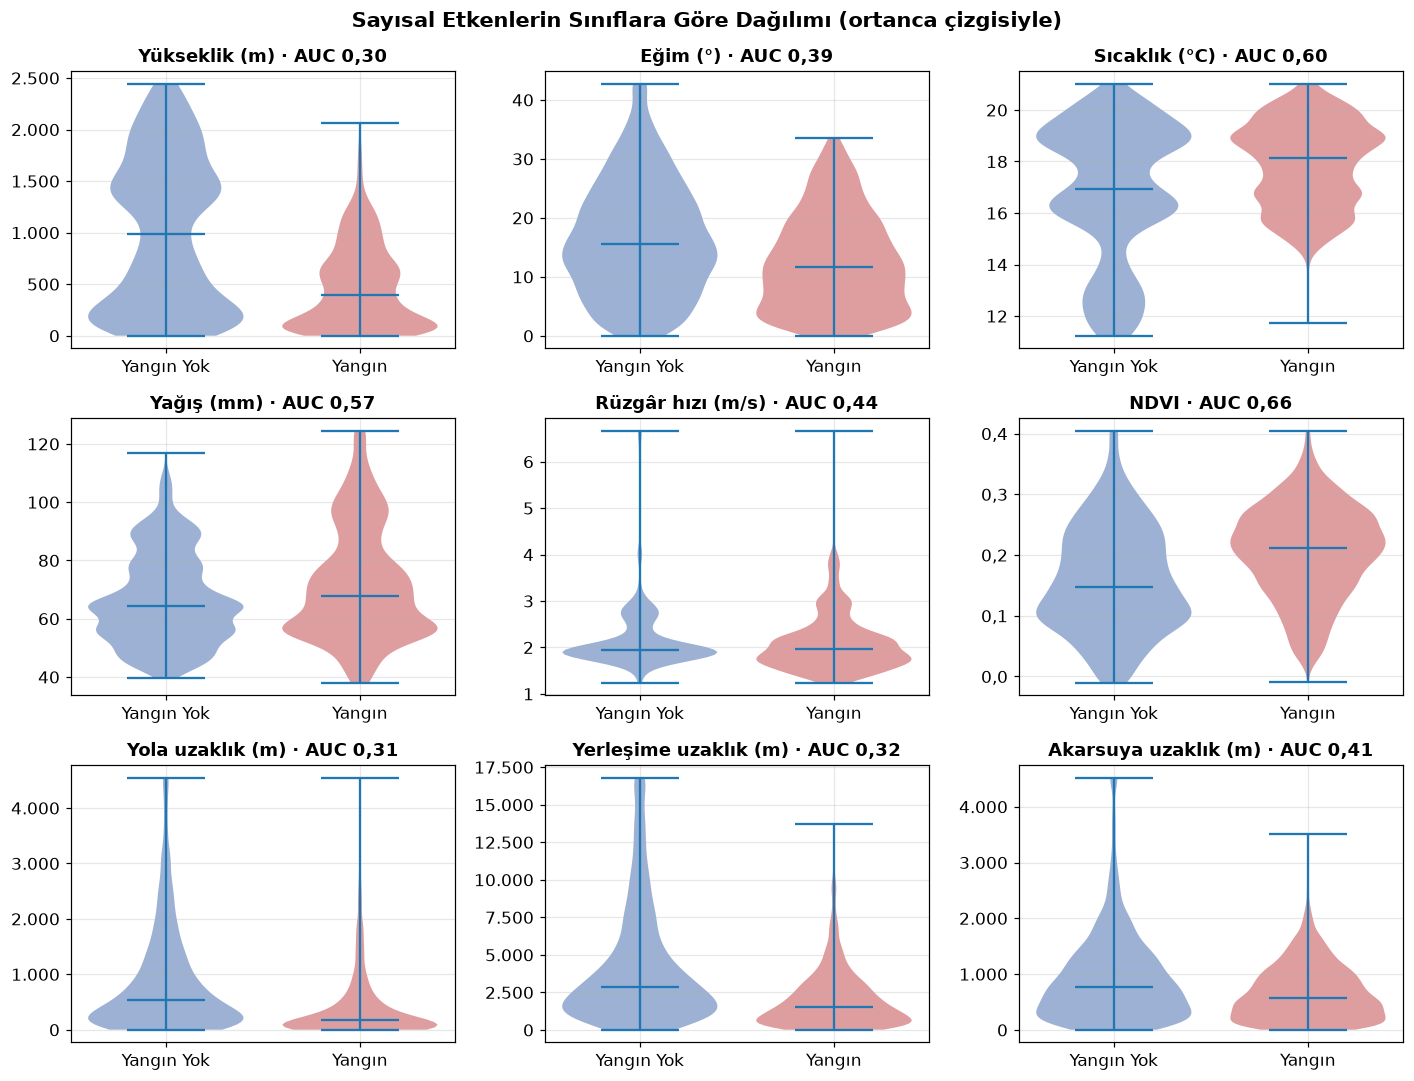

Sinif             Yangın Yok    Yangın  tek değişkenli AUC
Yukseklik            986.500   391.177               0.295
Yol_Uzaklik          529.123   171.073               0.309
Yerlesim_Uzaklik    2880.001  1520.275               0.315
Egim                  15.532    11.660               0.385
Akarsu_Uzaklik       762.049   575.149               0.412
Ruzgar_Hizi            1.950     1.956               0.442
Yagis                 64.296    67.729               0.571
Sicaklik              16.947    18.145               0.599
NDVI                   0.148     0.212               0.661


In [6]:
from sklearn.metrics import roc_auc_score
tek_auc = {c: float(roc_auc_score(df[o.HEDEF], df[c])) for c in o.SAYISAL}
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), o.SAYISAL):
    veri = [df.loc[df[o.HEDEF] == k, c] for k in (0, 1)]
    alt, ust = df[c].quantile(0.005), df[c].quantile(0.995)
    parca = ax.violinplot([v.clip(alt, ust) for v in veri], showmedians=True, widths=0.8)
    for govde, renk in zip(parca["bodies"], ["#4c72b0", "#c44e52"]):
        govde.set_facecolor(renk); govde.set_alpha(0.55)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Yangın Yok", "Yangın"])
    birim = f" ({o.BIRIM[c]})" if o.BIRIM[c] else ""
    ax.set_title(f"{o.OKUNUR[c]}{birim} · AUC {o.sayi(tek_auc[c], 2)}", fontsize=12)
fig.suptitle("Sayısal Etkenlerin Sınıflara Göre Dağılımı (ortanca çizgisiyle)", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_dagilimlar.png"), bbox_inches="tight")
plt.show()
ortanca = df.groupby("Sinif", observed=True)[o.SAYISAL].median().T
ortanca["tek değişkenli AUC"] = pd.Series(tek_auc)
print(ortanca.round(3).sort_values("tek değişkenli AUC").to_string())
EK["tek_auc"] = tek_auc

### 5. Bakı

Bakı, yamacın baktığı yöndür. Kuzey yarımkürede güneye bakan yamaçlar daha çok güneş
alır, daha sıcak ve kuru olur; bu yüzden yangına daha yatkın olmaları beklenir. Bakı
dairesel bir değişken olduğu için (kuzey ile kuzeybatı birbirine yakındır, 0° ile 315°
sayısal olarak uzak görünse de) modellerde sin ve cos bileşenleriyle kodlanmıştır.

            mean  size
Baki                  
Kuzey      0.450  1161
Kuzeydoğu  0.468   603
Doğu       0.525   631
Güneydoğu  0.539   623
Güney      0.559   732
Güneybatı  0.514   736
Batı       0.486   623
Kuzeybatı  0.457   685
Düz        0.437   616


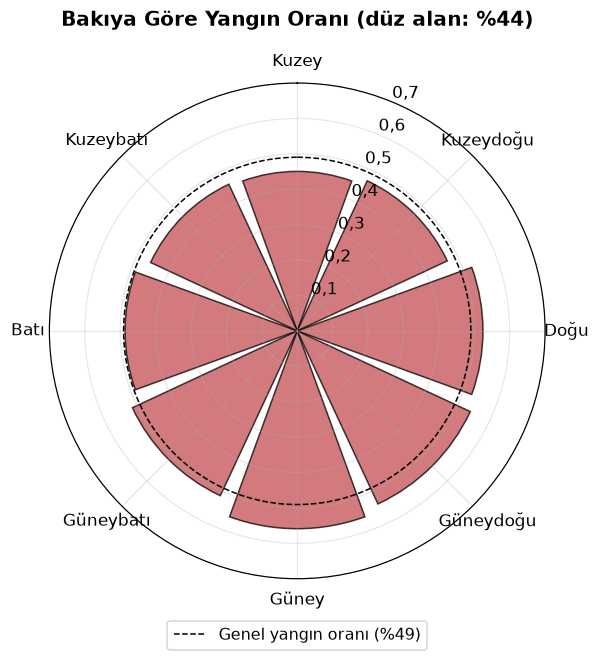

In [7]:
YON = ["Kuzey", "Kuzeydoğu", "Doğu", "Güneydoğu", "Güney", "Güneybatı", "Batı", "Kuzeybatı"]
baki = df.groupby("Baki")[o.HEDEF].agg(["mean", "size"])
print(baki.reindex(YON + ["Düz"]).round(3).to_string())
fig = plt.figure(figsize=(6.2, 6.2))
ax = fig.add_subplot(projection="polar")
aci = np.deg2rad(np.arange(0, 360, 45))
oran = baki.reindex(YON)["mean"].values
ax.bar(aci, oran, width=np.deg2rad(40), color="#c44e52", alpha=0.75, edgecolor="k")
ax.plot(np.linspace(0, 2 * np.pi, 200), np.full(200, df[o.HEDEF].mean()), "k--", lw=1,
        label=f"Genel yangın oranı (%{df[o.HEDEF].mean() * 100:.0f})")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_xticks(aci); ax.set_xticklabels(YON)
ax.set_ylim(0, max(0.7, oran.max() + 0.05))
ax.set_title(f"Bakıya Göre Yangın Oranı (düz alan: %{baki.loc['Düz', 'mean'] * 100:.0f})", pad=18)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.16))
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_baki.png"), bbox_inches="tight")
plt.show()
EK["baki_oran"] = {k: float(v) for k, v in baki["mean"].items()}

### 6. Etkenlerle Yangın Oranı Arasındaki İlişki

Her sayısal etken on eşit gruba (ondalık dilim) ayrılır ve her dilimdeki yangın oranı
hesaplanır. Bu grafik, etkilerin yönünü ve doğrusal olup olmadığını gösterir. Doğrusal
olmayan, eşikli ya da tepe yapan ilişkiler, ağaç tabanlı yöntemlerin doğrusal
yöntemlerden neden daha başarılı olacağının ilk işaretidir.

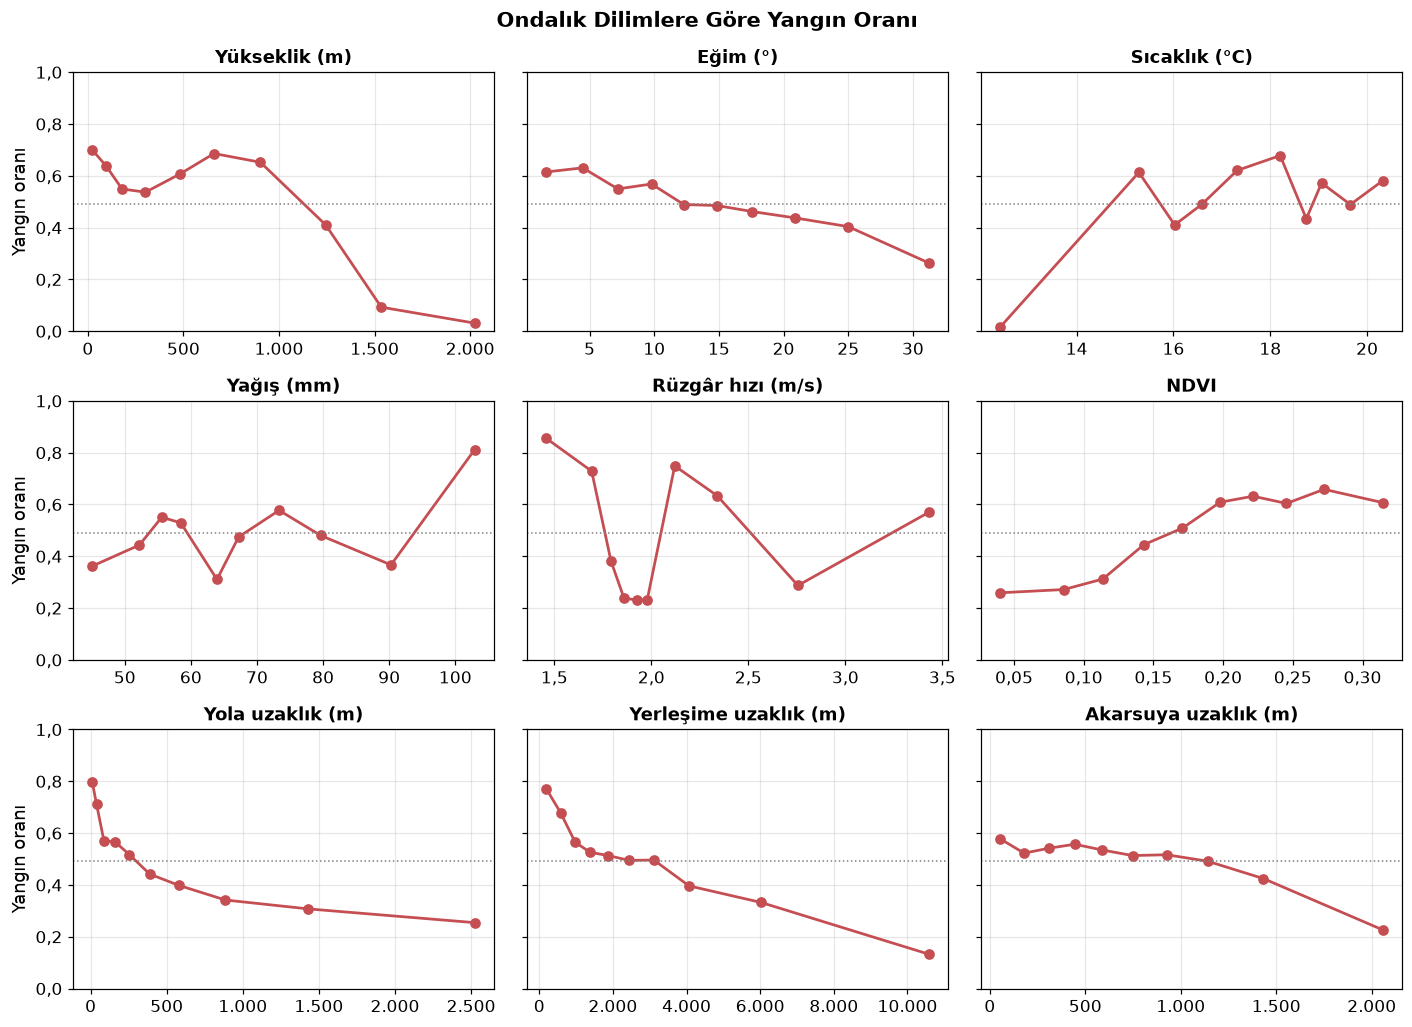

           Yükseklik: en düşük dilim %  70 → en yüksek dilim %   3
                Eğim: en düşük dilim %  61 → en yüksek dilim %  26
            Sıcaklık: en düşük dilim %   2 → en yüksek dilim %  58
               Yağış: en düşük dilim %  36 → en yüksek dilim %  81
         Rüzgâr hızı: en düşük dilim %  85 → en yüksek dilim %  57
                NDVI: en düşük dilim %  26 → en yüksek dilim %  61
        Yola uzaklık: en düşük dilim %  80 → en yüksek dilim %  25
   Yerleşime uzaklık: en düşük dilim %  77 → en yüksek dilim %  13
    Akarsuya uzaklık: en düşük dilim %  58 → en yüksek dilim %  23


In [8]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9.5), sharey=True)
dilim = {}
for ax, c in zip(axes.ravel(), o.SAYISAL):
    q = pd.qcut(df[c], 10, duplicates="drop")
    g = df.groupby(q, observed=True).agg(x=(c, "median"), oran=(o.HEDEF, "mean"))
    ax.plot(g["x"], g["oran"], "o-", color="#c44e52", lw=1.8)
    ax.axhline(df[o.HEDEF].mean(), color="gray", ls=":", lw=1)
    birim = f" ({o.BIRIM[c]})" if o.BIRIM[c] else ""
    ax.set_title(o.OKUNUR[c] + birim, fontsize=12)
    ax.set_ylim(0, 1)
    dilim[c] = {"x": g["x"].round(4).tolist(), "oran": g["oran"].round(4).tolist()}
for ax in axes[:, 0]:
    ax.set_ylabel("Yangın oranı")
fig.suptitle("Ondalık Dilimlere Göre Yangın Oranı", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_etkenler.png"), bbox_inches="tight")
plt.show()
for c in o.SAYISAL:
    print(f"{o.OKUNUR[c]:>20}: en düşük dilim %{dilim[c]['oran'][0] * 100:4.0f} → en yüksek dilim %{dilim[c]['oran'][-1] * 100:4.0f}")
EK["dilim"] = dilim

### 7. Korelasyon Yapısı

Yüksek korelasyonlu özellik çiftleri, doğrusal modellerde katsayıların yorumunu
zorlaştırır (çoklu doğrusallık) ve Naive Bayes'in bağımsızlık varsayımını çiğner. Bu
veri setinde en belirgin bağ yükseklik ile sıcaklık arasındadır: yükseldikçe hava soğur.

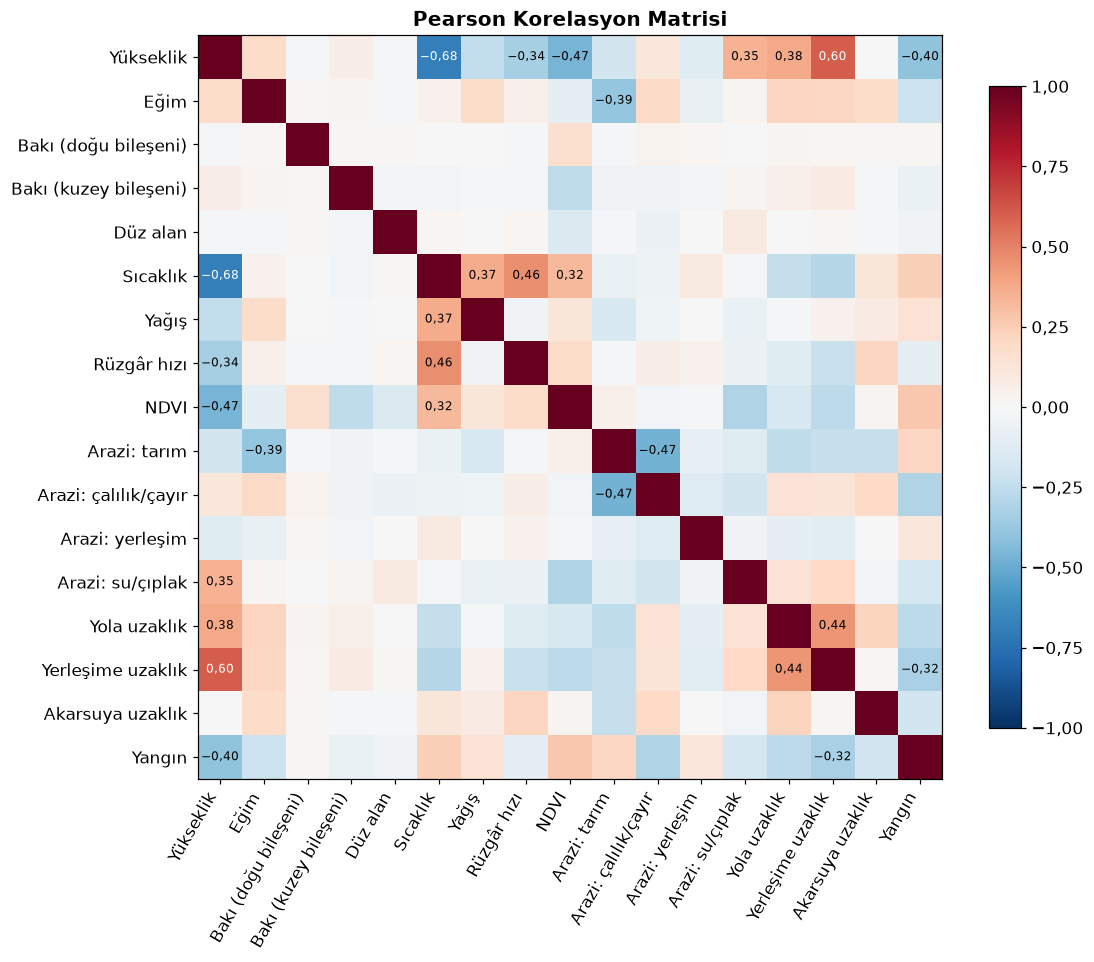

En güçlü 8 ilişki:
Yukseklik    Sicaklik           -0.680
             Yerlesim_Uzaklik    0.603
Arazi_Tarim  Arazi_Calilik      -0.470
Yukseklik    NDVI               -0.465
Sicaklik     Ruzgar_Hizi         0.464
Yol_Uzaklik  Yerlesim_Uzaklik    0.438
Yukseklik    Yangin             -0.401
Egim         Arazi_Tarim        -0.390

Hedefle korelasyon:
Yukseklik          -0.401
Yerlesim_Uzaklik   -0.321
Arazi_Calilik      -0.300
NDVI                0.267
Yol_Uzaklik        -0.260
Sicaklik            0.238
Egim               -0.213
Arazi_Tarim         0.208
Akarsu_Uzaklik     -0.194
Arazi_Su_Ciplak    -0.172
Yagis               0.148
Arazi_Yerlesim      0.114
Ruzgar_Hizi        -0.089
Baki_Cos           -0.069
Baki_Duz           -0.035
Baki_Sin            0.020


In [9]:
kor = df[o.OZELLIKLER + [o.HEDEF]].corr()
etiket = [o.OKUNUR[c] for c in kor.columns]
fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(kor.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(etiket))); ax.set_xticklabels(etiket, rotation=60, ha="right")
ax.set_yticks(range(len(etiket))); ax.set_yticklabels(etiket)
for i in range(len(etiket)):
    for j in range(len(etiket)):
        v = kor.values[i, j]
        if abs(v) >= 0.3 and i != j:
            ax.text(j, i, o.sayi(v, 2), ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
ax.set_title("Pearson Korelasyon Matrisi")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_korelasyon.png"), bbox_inches="tight")
plt.show()
ust = kor.where(np.triu(np.ones(kor.shape, bool), 1)).stack().sort_values(key=np.abs, ascending=False)
print("En güçlü 8 ilişki:")
print(ust.head(8).round(3).to_string())
print()
print("Hedefle korelasyon:")
print(kor[o.HEDEF].drop(o.HEDEF).sort_values(key=np.abs, ascending=False).round(3).to_string())
EK["korelasyon_hedef"] = {k: float(v) for k, v in kor[o.HEDEF].drop(o.HEDEF).items()}
EK["korelasyon_en_guclu"] = [[a, b, float(v)] for (a, b), v in ust.head(8).items()]

### 8. Sözde Mekânsal İklim Grupları

Veri setinde koordinat yoktur. Ancak sıcaklık, yağış ve rüzgâr değerleri meteoroloji
istasyonlarının ölçümlerinden **enterpolasyonla** üretilmiş düzgün yüzeylerden okunmuştur;
birbirine yakın noktalar neredeyse aynı iklim değerlerini taşır. Bu nedenle bir noktanın
iklim değerleri, konumunun bir "parmak izi" gibi davranır. Noktalar bu üç değişkene göre
k-ortalamalar yöntemiyle 25 gruba ayrılmıştır (`_builder/veri_hazirla.py`). Her grup
yaklaşık bir bölgeye karşılık gelir. Grupların çoğunda yangın oranı genel ortalamadan
belirgin biçimde sapar: yangınlar mekânda kümelenmiştir.

İklim uzayında en yakın komşusu aynı sınıfta olan nokta oranı: %95.6
Yangın oranı %80'in üstünde ya da %20'nin altında olan grup oranı: %36
             Nokta  Yangin_Orani  Sicaklik    Yagis
Iklim_Grubu                                        
1              377         0.008    11.906   45.398
2              344         0.029    13.318   51.936
3               87         1.000    14.967  122.105
4              151         0.848    15.372   45.658
5              372         0.449    15.456   60.790
6              141         0.688    16.103   89.943
7              327         0.349    16.152   70.190
8              174         0.546    16.404   78.567
9              199         0.678    16.571  104.993
10             455         0.233    16.694   63.409
11             312         0.949    16.732   49.654
12             199         0.729    17.661   76.727
13             450         0.640    18.012   64.225
14             215         0.679    18.515   56.500
15             319         0

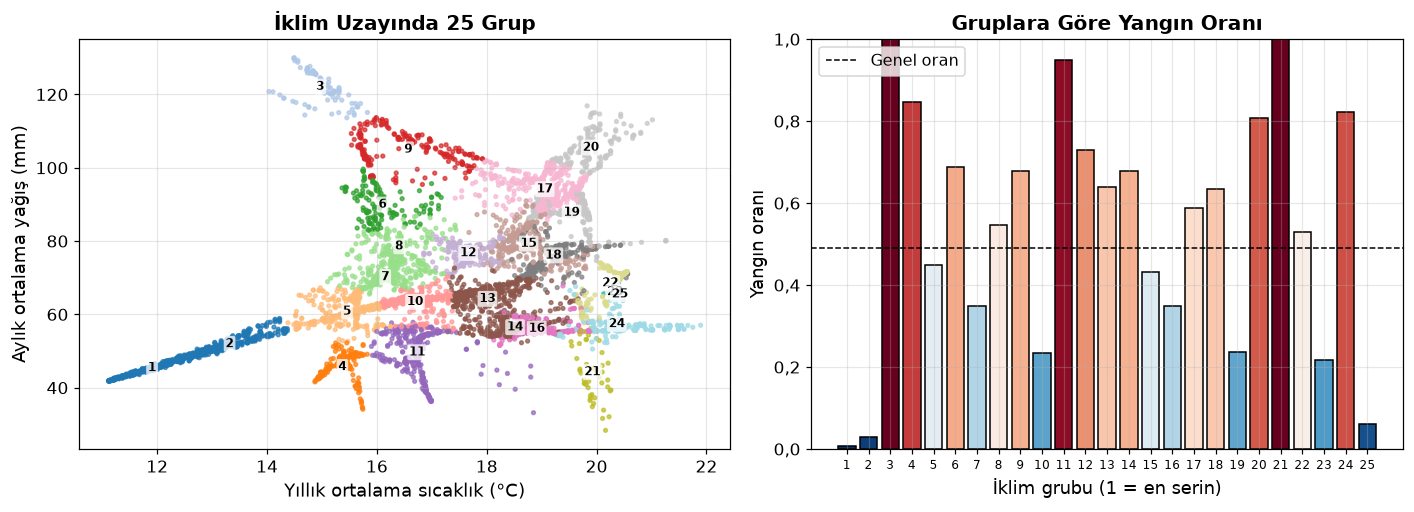

In [10]:
grup = df.groupby(o.GRUP).agg(Nokta=(o.HEDEF, "size"), Yangin_Orani=(o.HEDEF, "mean"),
                               Sicaklik=("Sicaklik", "mean"), Yagis=("Yagis", "mean"))
from sklearn.neighbors import NearestNeighbors
z = (df[o.IKLIM] - df[o.IKLIM].mean()) / df[o.IKLIM].std()
_, komsu = NearestNeighbors(n_neighbors=2).fit(z).kneighbors(z)
ayni_sinif = float((df[o.HEDEF].values[komsu[:, 1]] == df[o.HEDEF].values).mean())
saf = float(((grup.Yangin_Orani >= 0.8) | (grup.Yangin_Orani <= 0.2)).mean())
print(f"İklim uzayında en yakın komşusu aynı sınıfta olan nokta oranı: %{ayni_sinif * 100:.1f}")
print(f"Yangın oranı %80'in üstünde ya da %20'nin altında olan grup oranı: %{saf * 100:.0f}")
print(grup.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
sc = ax.scatter(df["Sicaklik"], df["Yagis"], c=df[o.GRUP], cmap="tab20", s=6, alpha=0.7)
for g, r in grup.iterrows():
    ax.text(r.Sicaklik, r.Yagis, str(g), fontsize=8, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.75, lw=0))
ax.set_xlabel("Yıllık ortalama sıcaklık (°C)")
ax.set_ylabel("Aylık ortalama yağış (mm)")
ax.set_title("İklim Uzayında 25 Grup")
ax = axes[1]
renk = plt.cm.RdBu_r(grup.Yangin_Orani.values)
ax.bar(grup.index.astype(str), grup.Yangin_Orani, color=renk, edgecolor="k")
ax.axhline(df[o.HEDEF].mean(), color="k", ls="--", lw=1, label="Genel oran")
ax.set_xlabel("İklim grubu (1 = en serin)")
ax.set_ylabel("Yangın oranı")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", labelsize=8)
ax.set_title("Gruplara Göre Yangın Oranı")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_iklim_gruplari.png"), bbox_inches="tight")
plt.show()
EK["grup"] = {"ayni_sinif_komsu": ayni_sinif, "saf_grup_orani": saf,
              "oran_min": float(grup.Yangin_Orani.min()), "oran_max": float(grup.Yangin_Orani.max()),
              "boyut_min": int(grup.Nokta.min()), "boyut_max": int(grup.Nokta.max())}

### 9. Bölünme Seçiminin Gerekçesi: Rastgele ve Sözde Mekânsal Bölünme

Rastgele bir %80/%20 bölünmesinde, bir test noktasının iklim grubundaki "kardeş"
noktalar eğitimde kalır. Model, test noktasını bölgesinden tanıyarak doğru bilebilir;
bu, modelin yeni bir bölgede ne kadar başarılı olacağını söylemez. Bunu sayısal olarak
göstermek için aynı model (LightGBM, varsayılan ayarlar) üç farklı özellik kümesiyle iki
farklı doğrulama düzeninde (5 katlı rastgele ve 5 katlı sözde mekânsal grup) sınanmıştır.
İki düzen arasındaki fark, rastgele bölünmenin sonuçları ne kadar şişirdiğini gösterir.
Kitapta ana sonuçlar alanyazınla karşılaştırılabilirlik için rastgele bölünmeyle verilir,
her algoritmanın güvenilirlik sınaması ise sözde mekânsal grup doğrulamasıyla yapılır.

Tüm özellikler (16)    rastgele AUC = 0.9805 · sözde mekânsal AUC = 0.8795 · fark = +0.1010


İklim hariç (13)       rastgele AUC = 0.8942 · sözde mekânsal AUC = 0.8280 · fark = +0.0662


Yalnız iklim (3)       rastgele AUC = 0.9744 · sözde mekânsal AUC = 0.7665 · fark = +0.2080


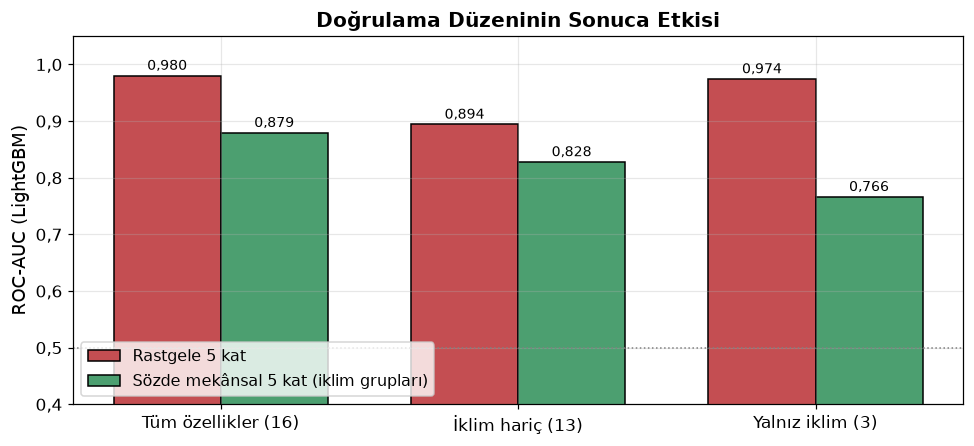

In [11]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold

kumeler = {"Tüm özellikler (16)": o.OZELLIKLER,
           "İklim hariç (13)": [c for c in o.OZELLIKLER if c not in o.IKLIM],
           "Yalnız iklim (3)": o.IKLIM}
rastgele_kat = list(StratifiedKFold(5, shuffle=True, random_state=42).split(df, df[o.HEDEF]))
grup_kat = [(df.index.get_indexer(a), df.index.get_indexer(b)) for a, b in o.grup_katlari(df)]
sizinti = {}
for ad, oz in kumeler.items():
    sonuc = {}
    for duzen, katlar in (("rastgele", rastgele_kat), ("grup", grup_kat)):
        auc = []
        for a, b in katlar:
            m = LGBMClassifier(random_state=42, verbose=-1).fit(df[oz].iloc[a], df[o.HEDEF].iloc[a])
            auc.append(roc_auc_score(df[o.HEDEF].iloc[b], m.predict_proba(df[oz].iloc[b])[:, 1]))
        sonuc[duzen] = float(np.mean(auc))
    sizinti[ad] = sonuc
    print(f"{ad:22s} rastgele AUC = {sonuc['rastgele']:.4f} · sözde mekânsal AUC = {sonuc['grup']:.4f} · "
          f"fark = {sonuc['rastgele'] - sonuc['grup']:+.4f}")
EK["sizinti"] = sizinti

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(sizinti)); w = 0.36
ax.bar(x - w / 2, [v["rastgele"] for v in sizinti.values()], w, label="Rastgele 5 kat", color="#c44e52", edgecolor="k")
ax.bar(x + w / 2, [v["grup"] for v in sizinti.values()], w, label="Sözde mekânsal 5 kat (iklim grupları)", color="#4c9f70", edgecolor="k")
for i, v in enumerate(sizinti.values()):
    ax.text(i - w / 2, v["rastgele"] + 0.01, o.sayi(v['rastgele'], 3), ha="center", fontsize=9)
    ax.text(i + w / 2, v["grup"] + 0.01, o.sayi(v['grup'], 3), ha="center", fontsize=9)
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set_xticks(x); ax.set_xticklabels(list(sizinti.keys()))
ax.set_ylabel("ROC-AUC (LightGBM)")
ax.set_ylim(0.4, 1.05)
ax.set_title("Doğrulama Düzeninin Sonuca Etkisi")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "eda_sizinti.png"), bbox_inches="tight")
plt.show()

### 10. Eğitim/Test Bölünmesi ve Taban Çizgileri

Aşağıdaki değerler, kitap boyunca başvurulacak ölçütlerdir. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı, "karar kütüğü"); bir modelin
işe yaradığını söyleyebilmek için asıl geçilmesi gereken çizgi budur.

In [12]:
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print()
print("Eğitim kümesi sınıf dağılımı:")
print(yc_tr.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())
print()
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())
print()
tb = o.taban_cizgileri(df)
k = tb["kural"]
print(f"Öğrenilen tek kural: {o.OKUNUR[k['ozellik']]} ≤ {k['esik']:.1f} → yangın oranı {k['sol_oran']:.3f}; "
      f"üstünde → {k['sag_oran']:.3f}")
print("TABAN 1 — çoğunluk sınıfı:", tb["cogunluk_sinifi"])
for kk, v in tb["siniflandirma"].items():
    print(f"    {kk:>14}: {v:.4f}")
print("TABAN 2 — tek kural (sınıflandırma)")
for kk, v in tb["kural_siniflandirma"].items():
    print(f"    {kk:>14}: {v:.4f}")
print(f"TABAN 3 — eğitim kümesinin yangın oranı ({tb['egitim_yangin_orani']:.4f})")
for kk, v in tb["regresyon"].items():
    print(f"    {kk:>6}: {v:.4f}")
print("TABAN 4 — tek kural (duyarlılık skoru)")
for kk, v in tb["kural_regresyon"].items():
    print(f"    {kk:>6}: {v:.4f}")
EK["taban"] = tb
EK["test_yangin_orani"] = float(yr_te.mean())

Eğitim: 5128 nokta  |  Test: 1282 nokta

Eğitim kümesi sınıf dağılımı:
Sinif
Yangın Yok    2613
Yangın        2515

Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629

Öğrenilen tek kural: Yükseklik ≤ 1258.0 → yangın oranı 0.622; üstünde → 0.084
TABAN 1 — çoğunluk sınıfı: Yangın Yok
          Accuracy: 0.5094
       BalancedAcc: 0.5000
          F1_macro: 0.3375
       F1_weighted: 0.3438
TABAN 2 — tek kural (sınıflandırma)
          Accuracy: 0.6934
       BalancedAcc: 0.6982
          F1_macro: 0.6748
       F1_weighted: 0.6733
TABAN 3 — eğitim kümesinin yangın oranı (0.4904)
       MAE: 0.4998
       MSE: 0.2499
      RMSE: 0.4999
        R2: -0.0000
       AUC: 0.5000
TABAN 4 — tek kural (duyarlılık skoru)
       MAE: 0.3931
       MSE: 0.1978
      RMSE: 0.4447
        R2: 0.2086
       AUC: 0.6982


In [13]:
ozet = o.sozluk_json_yaz(df, ek=EK)
print("Kitap metnindeki veri bölümü bu dosyadan beslenir.")

Veri özeti kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\_veri_ozeti.json
Kitap metnindeki veri bölümü bu dosyadan beslenir.



---

# BÖLÜM 2 — Lojistik Regresyon

*Bu bölümün kaynak defteri:* `01_lojistik_regresyon.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Lojistik regresyon, adındaki "regresyon" sözcüğüne karşın bir **sınıflandırma**
yöntemidir. Özelliklerin doğrusal bir bileşimini lojistik (sigmoid) fonksiyondan geçirerek
bir noktanın yangın noktası olma olasılığını üretir; olasılık 0,5'i aşarsa nokta "Yangın"
olarak etiketlenir. Hızlıdır, karar sınırı yorumlanabilir ve katsayılarının işareti
özelliğin etki yönünü doğrudan gösterir. Yangın duyarlılığı alanyazınında en sık kullanılan
istatistiksel yöntemlerden biridir. Katsayıların karşılaştırılabilmesi ve optimizasyonun
dengeli ilerlemesi için özellikler ölçeklenir.

### 1. Veri Hazırlığı

Ölçekleme **yalnızca eğitim kümesine** oturtulur, teste dönüştürülerek uygulanır.
Ölçekleyiciyi bütün veriye oturtmak, test kümesinin ortalama ve varyans bilgisinin
eğitime sızmasına (data leakage) yol açar ve sonuçları iyimser biçimde saptırır.

In [14]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
tb = o.taban_cizgileri(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Model Eğitimi ve Test Performansı

`max_iter=2000` yalnızca yakınsama uyarısını önlemek içindir; modelin matematiğini
değiştirmez. `class_weight='balanced'` iki sınıfın ağırlığını sıklıklarıyla ters orantılı
yapar. Bu veri setinde sınıflar zaten neredeyse dengelidir (yaklaşık yarı yarıya); ayar,
bütün sınıflandırıcılarda aynı yöntembilimin izlenmesi için korunmuştur.

In [15]:
clf = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
clf.fit(X_tr_s, yc_tr)
yp = clf.predict(X_te_s)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
olasilik = clf.predict_proba(X_te_s)[:, list(clf.classes_).index(o.POZITIF)]
auc = o.reg_metrikleri(yr_te, olasilik)["AUC"]
print(f"{'ROC-AUC':>14}: {auc:.4f}  (yangın olasılığının sıralama başarısı)")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.7348
   BalancedAcc: 0.7351
      F1_macro: 0.7348
   F1_weighted: 0.7348
       ROC-AUC: 0.8291  (yangın olasılığının sıralama başarısı)

              precision    recall  f1-score   support

  Yangın Yok      0.750     0.720     0.734       653
      Yangın      0.721     0.750     0.735       629

    accuracy                          0.735      1282
   macro avg      0.735     0.735     0.735      1282
weighted avg      0.735     0.735     0.735      1282



#### 2.1 Taban Çizgileriyle Karşılaştırma

Bir sınıflandırma sonucunun anlamlı olup olmadığı iki ölçüte göre okunur: hiçbir şey
bilmeyen **çoğunluk sınıfı** tahmini ve eğitim kümesinden öğrenilmiş **tek bir eşik
sorusu** ("yükseklik şu değerin altındaysa yangın") ile yapılan tahmin. Asıl geçilmesi
gereken çizgi ikincisidir.

In [16]:
print("Taban çizgileri")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f} ise Yangın, değilse Yangın Yok")

Taban çizgileri
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.7348 |   0.5094 |    0.6934 | +0.0413
     BalancedAcc |  0.7351 |   0.5000 |    0.6982 | +0.0369
        F1_macro |  0.7348 |   0.3375 |    0.6748 | +0.0600
     F1_weighted |  0.7348 |   0.3438 |    0.6733 | +0.0614
Tek kural: Yükseklik ≤ 1258.0 ise Yangın, değilse Yangın Yok


In [17]:
o.karmasiklik_grafigi(yc_te, yp, "Lojistik Regresyon", "lojistik")

Lojistik Regresyon — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   470    183
      Yangın |   157    472


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\lojistik_siniflandirma.png'

### 3. Algoritmaya Özgü Analiz: Katsayıların Yorumu

Özellikler standartlaştırıldığı için katsayılar doğrudan karşılaştırılabilir: bir
katsayı, ilgili özelliğin bir standart sapmalık artışının "Yangın" sınıfının
log-olasılığını (log-odds) ne kadar değiştirdiğini gösterir. Pozitif katsayı yangın
olasılığını artırır, negatif katsayı azaltır. Arazi örtüsü göstergelerinin katsayıları
**orman alanına göre** okunur.

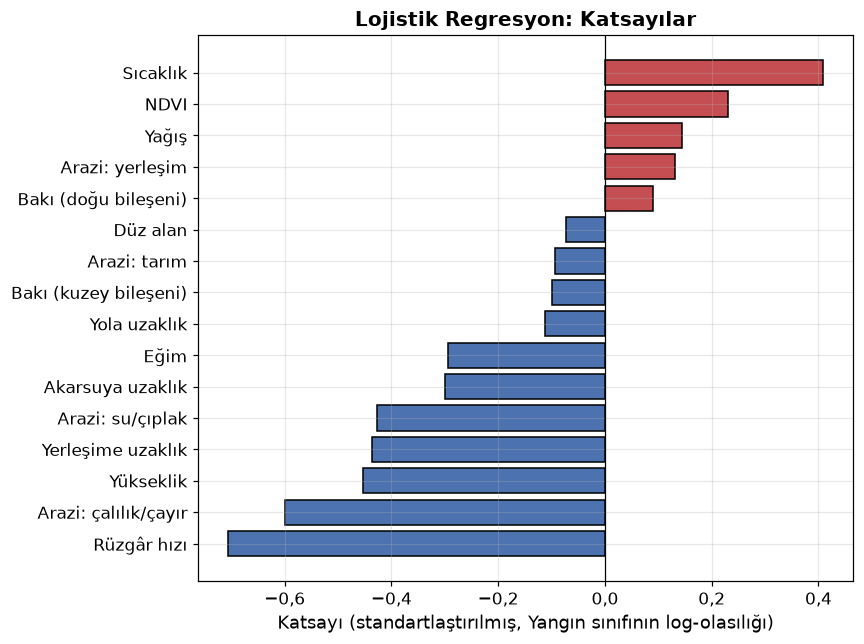

Ruzgar_Hizi        -0.706
Arazi_Calilik      -0.600
Yukseklik          -0.453
Yerlesim_Uzaklik   -0.437
Arazi_Su_Ciplak    -0.426
Sicaklik            0.409
Akarsu_Uzaklik     -0.300
Egim               -0.293
NDVI                0.230
Yagis               0.144
Arazi_Yerlesim      0.130
Yol_Uzaklik        -0.112
Baki_Cos           -0.099
Arazi_Tarim        -0.093
Baki_Sin            0.090
Baki_Duz           -0.073

Yangın olasılığını en çok artıran üç özellik : ['Sicaklik', 'NDVI', 'Yagis']
Yangın olasılığını en çok azaltan üç özellik: ['Ruzgar_Hizi', 'Arazi_Calilik', 'Yukseklik']

Olasılık oranları (bir std. sapmalık artış başına):
Sicaklik            1.505
NDVI                1.258
Yagis               1.155
Arazi_Yerlesim      1.139
Baki_Sin            1.094
Baki_Duz            0.930
Arazi_Tarim         0.911
Baki_Cos            0.906
Yol_Uzaklik         0.894
Egim                0.746
Akarsu_Uzaklik      0.741
Arazi_Su_Ciplak     0.653
Yerlesim_Uzaklik    0.646
Yukseklik           0.6

In [18]:
# İkili sınıflandırmada scikit-learn tek bir katsayı vektörü öğrenir; bu vektör
# clf.classes_ içindeki İKİNCİ sınıfın log-olasılığına aittir.
isaret = 1.0 if clf.classes_[1] == o.POZITIF else -1.0
katsayi = pd.Series(isaret * clf.coef_[0], index=o.OZELLIKLER)
s = katsayi.rename(index=o.OKUNUR).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(s.index, s.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in s.values], edgecolor="k")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Katsayı (standartlaştırılmış, Yangın sınıfının log-olasılığı)")
ax.set_title("Lojistik Regresyon: Katsayılar")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "lojistik_katsayi.png"), bbox_inches="tight")
plt.show()

print(katsayi.sort_values(key=np.abs, ascending=False).round(3).to_string())
print()
print("Yangın olasılığını en çok artıran üç özellik :", list(katsayi.sort_values().index[::-1][:3]))
print("Yangın olasılığını en çok azaltan üç özellik:", list(katsayi.sort_values().index[:3]))
oran = np.exp(katsayi)
print()
print("Olasılık oranları (bir std. sapmalık artış başına):")
print(oran.sort_values(ascending=False).round(3).to_string())

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [19]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    _olcek = o.StandardScaler().fit(Xa)
    Xa, Xb = _olcek.transform(Xa), _olcek.transform(Xb)
    c_tahmin = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(float("nan"))  # bu algoritma regresyon yapmaz
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +nan · F1-makro 0.6989
  kat 2: eğitim  4170 · sınama   958 · R² +nan · F1-makro 0.6511
  kat 3: eğitim  4114 · sınama  1014 · R² +nan · F1-makro 0.7058
  kat 4: eğitim  4055 · sınama  1073 · R² +nan · F1-makro 0.7476
  kat 5: eğitim  4150 · sınama   978 · R² +nan · F1-makro 0.6098
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +nan ± nan
  F1-makro: 0.6826 ± 0.0476


In [20]:
o.sonuc_kaydet("lojistik_regresyon", None, cls,
               ek={"cv": cv_ozet, "tahmin": [str(v) for v in yp], "auc": auc,
                   "katsayi": katsayi.round(5).to_dict(),
                   "olasilik_orani": oran.round(5).to_dict()})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\lojistik_regresyon.json


{'algoritma': 'lojistik_regresyon',
 'regresyon': None,
 'siniflandirma': {'Accuracy': 0.734789391575663,
  'BalancedAcc': 0.7350762166544529,
  'F1_macro': 0.734788746105919,
  'F1_weighted': 0.7347810004689908},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [None, None, None, None, None],
   'F1_macro': [0.6989360924489809,
    0.6510653797122564,
    0.7057688688123471,
    0.7475531714662149,
    0.6097752496959599],
   'R2_ort': None,
   'R2_std': None,
   'F1_ort': 0.6826197524271518,
   'F1_std': 0.04758246203132198},
  'tahmin': ['Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',


---

# BÖLÜM 3 — Lineer Regresyon

*Bu bölümün kaynak defteri:* `02_lineer_regresyon.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Lineer regresyon, hedef değişkeni özelliklerin doğrusal bir bileşimi olarak modeller.
Katsayıları, hata kareleri toplamını en aza indirecek biçimde (en küçük kareler)
çözer. Hedef 0/1 olduğunda bu modele **doğrusal olasılık modeli** denir: tahmin, bir
noktanın yangın noktası olma olasılığının doğrusal bir yaklaşımıdır. Tahminler 0–1
aralığının dışına taşabilir; bu, yöntemin bilinen bir zaafıdır ve lojistik regresyonun
neden geliştirildiğini de açıklar. En yalın regresyon yöntemi olduğu için diğer bütün
regresyon modellerine referans oluşturur: karmaşık bir model bu çizgiyi belirgin
biçimde geçemiyorsa, veride yakalanabilir doğrusal olmayan bir sinyal yok demektir.

### 1. Veri Hazırlığı

In [21]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
tb = o.taban_cizgileri(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)

6410 nokta · yangın 3144 · yangın yok 3266


Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']


### 2. Model Eğitimi ve Test Performansı

In [22]:
model = LinearRegression()
model.fit(X_tr, yr_tr)
y_pred = model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")
disari = float(((y_pred < 0) | (y_pred > 1)).mean())
print(f"\n0–1 aralığının dışına taşan tahmin oranı: %{disari * 100:.1f}")

print("\nÖğrenilen denklem (ham birimlerle):")
terimler = " + ".join(f"({c:+.6f} × {ad})" for c, ad in zip(model.coef_, o.OZELLIKLER))
print(f"  Skor = {model.intercept_:.4f} + {terimler}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.3568
   MSE: 0.1714
  RMSE: 0.4140
    R2: 0.3142
   AUC: 0.8288

0–1 aralığının dışına taşan tahmin oranı: %6.9

Öğrenilen denklem (ham birimlerle):
  Skor = 0.4229 + (-0.000104 × Yukseklik) + (-0.004901 × Egim) + (+0.020760 × Baki_Sin) + (-0.023373 × Baki_Cos) + (-0.047516 × Baki_Duz) + (+0.035744 × Sicaklik) + (+0.001320 × Yagis) + (-0.150679 × Ruzgar_Hizi) + (+0.464365 × NDVI) + (-0.024436 × Arazi_Tarim) + (-0.228034 × Arazi_Calilik) + (+0.126125 × Arazi_Yerlesim) + (-0.286902 × Arazi_Su_Ciplak) + (-0.000020 × Yol_Uzaklik) + (-0.000020 × Yerlesim_Uzaklik) + (-0.000068 × Akarsu_Uzaklik)


#### 2.1 Taban Çizgileriyle Karşılaştırma

Regresyonda iki taban kullanılır. **Ortalama tabanı** her test noktasına eğitim
kümesinin yangın oranını atar; R² = 0 ve AUC = 0,5 bu tabana karşılık gelir. **Tek kural
tabanı** ise eğitim kümesinden öğrenilmiş tek bir eşik sorusunun iki yanındaki yangın
oranlarını tahmin eder. Bir modelin işe yaradığını söyleyebilmek için asıl geçilmesi
gereken çizgi tek kuraldır.

In [23]:
print(f"Ortalama tabanı: eğitim kümesinin yangın oranı = {tb['egitim_yangin_orani']:.4f}")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = "iyi" if (k in o.BUYUK_IYI and fark > 0) or (k not in o.BUYUK_IYI and fark < 0) else "kötü"
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

Ortalama tabanı: eğitim kümesinin yangın oranı = 0.4904
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.3568 |   0.4998 |    0.3931 | -0.0362 (iyi)
     MSE |   0.1714 |   0.2499 |    0.1978 | -0.0264 (iyi)
    RMSE |   0.4140 |   0.4999 |    0.4447 | -0.0307 (iyi)
      R2 |   0.3142 |  -0.0000 |    0.2086 | +0.1056 (iyi)
     AUC |   0.8288 |   0.5000 |    0.6982 | +0.1306 (iyi)


In [24]:
o.reg_grafikleri(yr_te, y_pred, "Lineer Regresyon", "lineer")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\lineer_regresyon.png'

### 3. Algoritmaya Özgü Analiz: Standartlaştırılmış Katsayılar

Ham katsayılar özelliklerin birimine bağlıdır (yükseklik metre, uzaklıklar metre,
sıcaklık °C, NDVI birimsizdir) ve doğrudan karşılaştırılamaz. Bu nedenle aynı model
standartlaştırılmış özelliklerle bir kez daha kurulur. Tahminler değişmez; yalnızca
katsayılar "bir standart sapmalık artış, yangın duyarlılık skorunu ne kadar değiştirir?"
sorusunun cevabına dönüşür.

İki modelin tahminleri arasındaki en büyük fark: 1.95e-14 (sayısal yuvarlama)


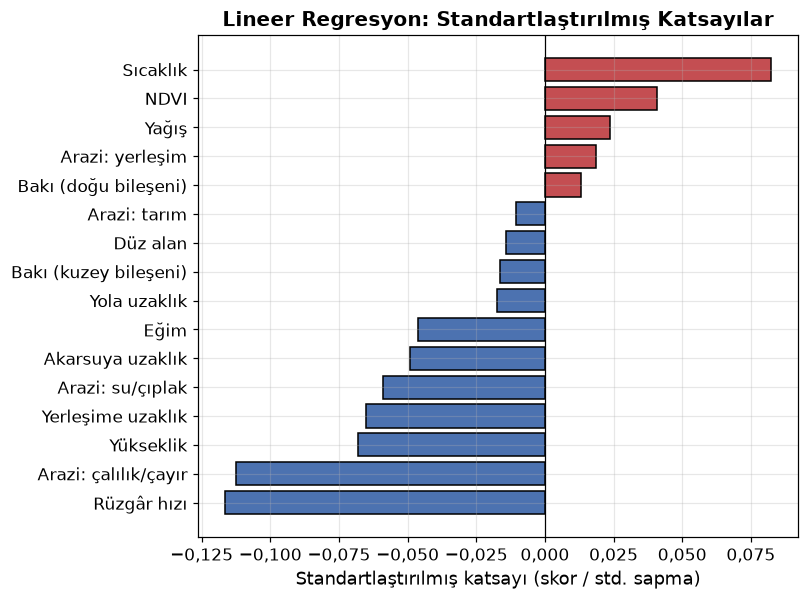

Ruzgar_Hizi        -0.116
Arazi_Calilik      -0.113
Sicaklik            0.082
Yukseklik          -0.068
Yerlesim_Uzaklik   -0.065
Arazi_Su_Ciplak    -0.059
Akarsu_Uzaklik     -0.049
Egim               -0.046
NDVI                0.041
Yagis               0.024
Arazi_Yerlesim      0.018
Yol_Uzaklik        -0.017
Baki_Cos           -0.017
Baki_Duz           -0.014
Baki_Sin            0.013
Arazi_Tarim        -0.010


In [25]:
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
std_model = LinearRegression().fit(X_tr_s, yr_tr)
fark_tahmin = float(np.max(np.abs(std_model.predict(X_te_s) - y_pred)))
print(f"İki modelin tahminleri arasındaki en büyük fark: {fark_tahmin:.2e} (sayısal yuvarlama)")
std_katsayi = pd.Series(std_model.coef_, index=o.OZELLIKLER)

s = std_katsayi.rename(index=o.OKUNUR).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.barh(s.index, s.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in s.values], edgecolor="k")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Standartlaştırılmış katsayı (skor / std. sapma)")
ax.set_title("Lineer Regresyon: Standartlaştırılmış Katsayılar")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "lineer_onem.png"), bbox_inches="tight")
plt.show()
print(std_katsayi.sort_values(key=np.abs, ascending=False).round(3).to_string())

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [26]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = LinearRegression().fit(Xa, yra).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(float("nan"))  # bu algoritma sınıflandırma yapmaz
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2578 · F1-makro nan
  kat 2: eğitim  4170 · sınama   958 · R² +0.1312 · F1-makro nan
  kat 3: eğitim  4114 · sınama  1014 · R² +0.2997 · F1-makro nan
  kat 4: eğitim  4055 · sınama  1073 · R² +0.2979 · F1-makro nan
  kat 5: eğitim  4150 · sınama   978 · R² +0.0765 · F1-makro nan
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.2126 ± 0.0917
  F1-makro: nan ± nan


In [27]:
o.sonuc_kaydet("lineer_regresyon", reg, None,
               ek={"denklem": f"Skor = {model.intercept_:.4f} + {terimler}",
                   "std_katsayi": std_katsayi.round(5).to_dict(), "cv": cv_ozet,
                   "aralik_disi_oran": disari, "tahmin": np.round(y_pred, 4).tolist()})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\lineer_regresyon.json


{'algoritma': 'lineer_regresyon',
 'regresyon': {'MAE': 0.3568175627081385,
  'MSE': 0.17139340981342066,
  'RMSE': 0.4139968717435201,
  'R2': 0.3141860059595498,
  'AUC': 0.828754166291325},
 'siniflandirma': None,
 'ek': {'denklem': 'Skor = 0.4229 + (-0.000104 × Yukseklik) + (-0.004901 × Egim) + (+0.020760 × Baki_Sin) + (-0.023373 × Baki_Cos) + (-0.047516 × Baki_Duz) + (+0.035744 × Sicaklik) + (+0.001320 × Yagis) + (-0.150679 × Ruzgar_Hizi) + (+0.464365 × NDVI) + (-0.024436 × Arazi_Tarim) + (-0.228034 × Arazi_Calilik) + (+0.126125 × Arazi_Yerlesim) + (-0.286902 × Arazi_Su_Ciplak) + (-0.000020 × Yol_Uzaklik) + (-0.000020 × Yerlesim_Uzaklik) + (-0.000068 × Akarsu_Uzaklik)',
  'std_katsayi': {'Yukseklik': -0.06811,
   'Egim': -0.0461,
   'Baki_Sin': 0.01312,
   'Baki_Cos': -0.01651,
   'Baki_Duz': -0.01404,
   'Sicaklik': 0.08225,
   'Yagis': 0.02361,
   'Ruzgar_Hizi': -0.11634,
   'NDVI': 0.0407,
   'Arazi_Tarim': -0.01043,
   'Arazi_Calilik': -0.11251,
   'Arazi_Yerlesim': 0.01843,
 


---

# BÖLÜM 4 — K-En Yakın Komşu (KNN)

*Bu bölümün kaynak defteri:* `03_knn.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

KNN, tahmin için özellik uzayındaki en yakın **k** komşuya bakar: regresyonda bu
komşuların ortalamasını, sınıflandırmada çoğunluk oyunu kullanır. Ayrı bir "öğrenme"
aşaması yoktur; bütün iş tahmin anında yapılır, bu yüzden tembel (lazy) öğrenici olarak
anılır. Uzaklık hesabına dayandığı için özelliklerin ölçeklenmesi zorunludur. Bu
çalışmada bir noktanın "komşuları", topografyası, iklimi, bitki örtüsü ve yerleşime
uzaklığı ona en çok benzeyen noktalardır. Komşu sayısı doğrulama kümesiyle **k = 10**
olarak seçilmiştir.

### 1. Veri Hazırlığı

In [28]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [29]:
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
reg_model = KNeighborsRegressor(n_neighbors=10)   # k = 10 (doğrulama kümesiyle seçildi)
reg_model.fit(X_tr_s, yr_tr)
y_pred = reg_model.predict(X_te_s)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.2368
   MSE: 0.1190
  RMSE: 0.3450
    R2: 0.5237
   AUC: 0.9077


In [30]:
o.reg_grafikleri(yr_te, y_pred, "k-En Yakın Komşu (KNN)", "knn")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\knn_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [31]:
clf = KNeighborsClassifier(n_neighbors=10)
clf.fit(X_tr_s, yc_tr)
yp = clf.predict(X_te_s)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.8385
   BalancedAcc: 0.8392
      F1_macro: 0.8385
   F1_weighted: 0.8384

              precision    recall  f1-score   support

  Yangın Yok      0.869     0.804     0.835       653
      Yangın      0.811     0.874     0.842       629

    accuracy                          0.839      1282
   macro avg      0.840     0.839     0.838      1282
weighted avg      0.841     0.839     0.838      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [32]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.2368 |   0.4998 |    0.3931 | -0.1562 (iyi)
     MSE |   0.1190 |   0.2499 |    0.1978 | -0.0788 (iyi)
    RMSE |   0.3450 |   0.4999 |    0.4447 | -0.0997 (iyi)
      R2 |   0.5237 |  -0.0000 |    0.2086 | +0.3151 (iyi)
     AUC |   0.9077 |   0.5000 |    0.6982 | +0.2095 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.8385 |   0.5094 |    0.6934 | +0.1451
     BalancedAcc |  0.8392 |   0.5000 |    0.6982 | +0.1410
        F1_macro |  0.8385 |   0.3375 |    0.6748 | +0.1637
     F1_weighted |  0.8384 |   0.3438 |    0.6733 | +0.1651
Tek kural: Yükseklik ≤ 1258.0


In [33]:
o.karmasiklik_grafigi(yc_te, yp, "k-En Yakın Komşu (KNN)", "knn")

k-En Yakın Komşu (KNN) — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   525    128
      Yangın |    79    550


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\knn_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### k Değerinin Etkisi

k, modelin karmaşıklığını belirleyen tek düğmedir. Küçük k → tahmin birkaç komşuya
bağlı kalır, gürültüye duyarlı olur (aşırı öğrenme). Büyük k → komşu havuzu genişler,
model ortalamaya doğru yassılaşır (eksik öğrenme). Aşağıdaki eğriler bu dengeyi test
kümesi üzerinde gösterir; seçim ise önceden, doğrulama kümesiyle yapılmıştır.

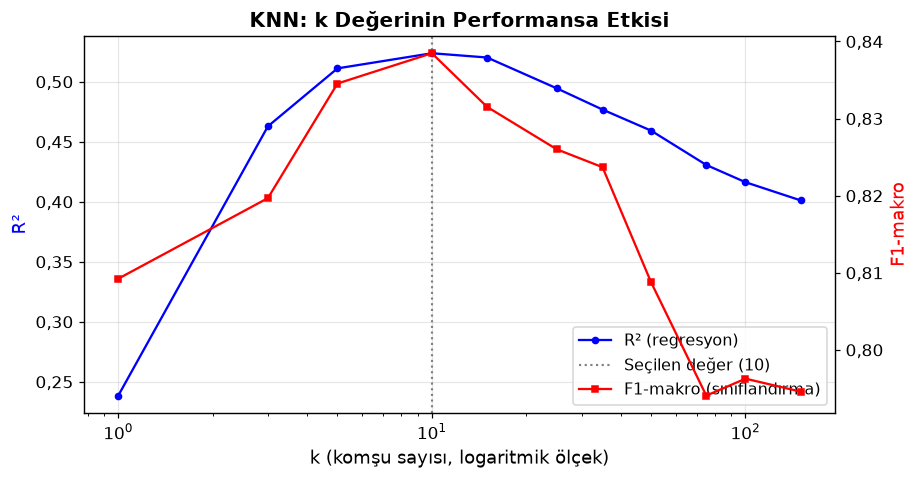

Tarama: [(1, 0.2384, 0.8092), (3, 0.4628, 0.8197), (5, 0.5111, 0.8345), (10, 0.5237, 0.8385), (15, 0.5201, 0.8315), (25, 0.4945, 0.826), (35, 0.4768, 0.8237), (50, 0.4592, 0.8088), (75, 0.4306, 0.7941), (100, 0.4162, 0.7963), (150, 0.4011, 0.7946)]
En yüksek R²: 0.5237 (10) · en yüksek F1-makro: 0.8385 (10)


In [34]:
degerler = [1, 3, 5, 10, 15, 25, 35, 50, 75, 100, 150]
r2_list, f1_list = [], []
for kk in degerler:
    r = KNeighborsRegressor(n_neighbors=kk).fit(X_tr_s, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te_s))["R2"])
    c = KNeighborsClassifier(n_neighbors=kk).fit(X_tr_s, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te_s))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(10, color="gray", ls=":", lw=1.4, label="Seçilen değer (10)")
ax1.set_xlabel("k (komşu sayısı, logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("KNN: k Değerinin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "knn_k_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [35]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    _olcek = o.StandardScaler().fit(Xa)
    Xa, Xb = _olcek.transform(Xa), _olcek.transform(Xb)
    r_tahmin = KNeighborsRegressor(n_neighbors=10).fit(Xa, yra).predict(Xb)
    c_tahmin = KNeighborsClassifier(n_neighbors=10).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2346 · F1-makro 0.7230
  kat 2: eğitim  4170 · sınama   958 · R² +0.1436 · F1-makro 0.6252
  kat 3: eğitim  4114 · sınama  1014 · R² +0.4292 · F1-makro 0.8181


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4189 · F1-makro 0.7974


  kat 5: eğitim  4150 · sınama   978 · R² +0.4979 · F1-makro 0.8374
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.3449 ± 0.1332
  F1-makro: 0.7602 ± 0.0779


In [36]:
o.sonuc_kaydet("knn", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\knn.json


{'algoritma': 'knn',
 'regresyon': {'MAE': 0.23681747269890796,
  'MSE': 0.11903276131045244,
  'RMSE': 0.3450112480926563,
  'R2': 0.5237020283052172,
  'AUC': 0.907674497306062},
 'siniflandirma': {'Accuracy': 0.8385335413416537,
  'BalancedAcc': 0.8391927194287342,
  'F1_macro': 0.8384721154495802,
  'F1_weighted': 0.8384131465931898},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.2346113811015612,
    0.1435961646038738,
    0.4292297276791448,
    0.4188662427022519,
    0.49794854417670675],
   'F1_macro': [0.7229568962126873,
    0.6251901191821085,
    0.8180981499391633,
    0.7973577598398642,
    0.8373850599053185],
   'R2_ort': 0.3448504120527077,
   'R2_std': 0.1331864604330558,
   'F1_ort': 0.7601975970158283,
   'F1_std': 0.07785261077778266},
  'duyarlilik': {'degerler': [1.0,
    3.0,
    5.0,
    10.0,
    15.0,
    25.0,
    35.0,
    50.0,
    75.0,
    100.0,
    150.0],
   'R2': [0.23842264027832893,
    0.46280358369359353,
    0.5110923048081861,
    0.


---

# BÖLÜM 5 — Destek Vektör Makineleri (SVM)

*Bu bölümün kaynak defteri:* `04_svm.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

SVM, sınıfları birbirinden ayıran **en geniş marjlı** sınırı arar. RBF çekirdeği
sayesinde doğrusal olmayan ilişkileri de yakalayabilir. Regresyon sürümü SVR, hatası
ε genişliğindeki bir tüpün içinde kalan örnekleri cezalandırmaz; sınıflandırma sürümü
SVC olarak adlandırılır. Marj kavramı mesafeye dayandığı için ölçekleme zorunludur.

**Hesaplama notu.** RBF çekirdekli SVM'nin eğitim süresi örnek sayısının yaklaşık
karesiyle büyür. Bu veri setinin eğitim kümesi birkaç bin noktadan oluştuğu için SVM
**bütün eğitim kümesiyle** eğitilir; alt örneklemeye gerek yoktur. Ceza parametresi
doğrulama kümesiyle **C = 1** olarak seçilmiştir.

### 1. Veri Hazırlığı

In [37]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVR, SVC
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [38]:
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
X_alt, yr_alt, yc_alt = o.alt_ornek(X_tr_s, yr_tr, yc_tr)   # sınır eğitim kümesinden büyük: tamamı kullanılır
print(f"SVM eğitim kümesi: {len(X_alt)} nokta (eğitim kümesinin %{len(X_alt) / len(X_tr) * 100:.1f}'i)")
reg_model = SVR(C=1)                        # C = 1 (doğrulama kümesiyle seçildi)
reg_model.fit(X_alt, yr_alt)
y_pred = reg_model.predict(X_te_s)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

SVM eğitim kümesi: 5128 nokta (eğitim kümesinin %100.0'i)


Test kümesi metrikleri
----------------------------------
   MAE: 0.2274
   MSE: 0.1136
  RMSE: 0.3370
    R2: 0.5455
   AUC: 0.9180


In [39]:
o.reg_grafikleri(yr_te, y_pred, "Destek Vektör Makineleri (SVM)", "svm")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\svm_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [40]:
clf = SVC(C=1, class_weight='balanced', random_state=42)
clf.fit(X_alt, yc_alt)
yp = clf.predict(X_te_s)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.8362
   BalancedAcc: 0.8368
      F1_macro: 0.8362
   F1_weighted: 0.8361

              precision    recall  f1-score   support

  Yangın Yok      0.864     0.806     0.834       653
      Yangın      0.811     0.868     0.839       629

    accuracy                          0.836      1282
   macro avg      0.838     0.837     0.836      1282
weighted avg      0.838     0.836     0.836      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [41]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.2274 |   0.4998 |    0.3931 | -0.1657 (iyi)
     MSE |   0.1136 |   0.2499 |    0.1978 | -0.0842 (iyi)
    RMSE |   0.3370 |   0.4999 |    0.4447 | -0.1077 (iyi)
      R2 |   0.5455 |  -0.0000 |    0.2086 | +0.3370 (iyi)
     AUC |   0.9180 |   0.5000 |    0.6982 | +0.2198 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.8362 |   0.5094 |    0.6934 | +0.1427
     BalancedAcc |  0.8368 |   0.5000 |    0.6982 | +0.1386
        F1_macro |  0.8362 |   0.3375 |    0.6748 | +0.1614
     F1_weighted |  0.8361 |   0.3438 |    0.6733 | +0.1628
Tek kural: Yükseklik ≤ 1258.0


In [42]:
o.karmasiklik_grafigi(yc_te, yp, "Destek Vektör Makineleri (SVM)", "svm")

Destek Vektör Makineleri (SVM) — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   526    127
      Yangın |    83    546


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\svm_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### C Parametresinin Etkisi

C, marj ihlallerine verilen cezayı denetler. Küçük C → yumuşak marj, daha çok hataya
izin verilir ve model düzleşir; büyük C → eğitim verisine sıkı uyum ve aşırı öğrenme
eğilimi. Etkiyi görmek için C değeri logaritmik olarak tarandı.

Destek vektörü sayısı: {'regresyon': 2813, 'siniflandirma': 2239}


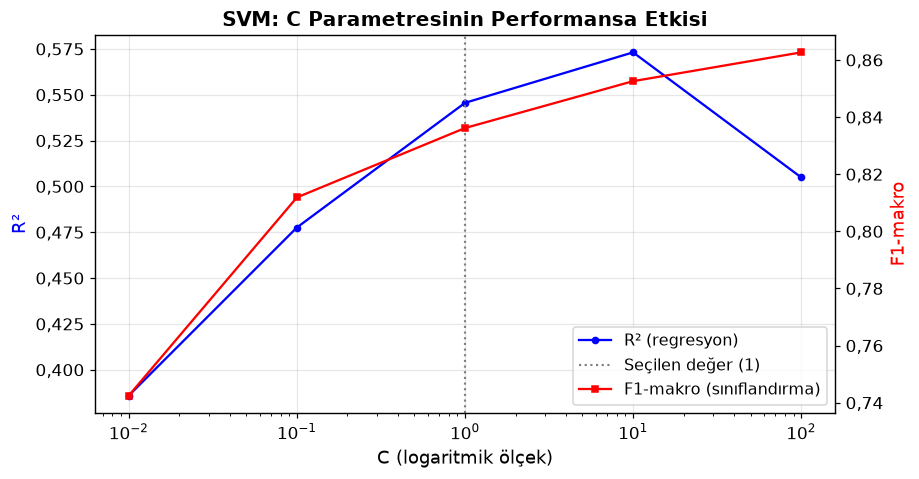

Tarama: [(0.01, 0.3859, 0.7425), (0.1, 0.4775, 0.8119), (1, 0.5455, 0.8362), (10, 0.5731, 0.8526), (100, 0.5049, 0.8626)]
En yüksek R²: 0.5731 (10) · en yüksek F1-makro: 0.8626 (100)


In [43]:
degerler = [0.01, 0.1, 1, 10, 100]
r2_list, f1_list = [], []
for CC in degerler:
    r = SVR(C=CC).fit(X_alt, yr_alt)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te_s))["R2"])
    c = SVC(C=CC, class_weight='balanced', random_state=42).fit(X_alt, yc_alt)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te_s))["F1_macro"])
destek = {"regresyon": int(len(reg_model.support_)), "siniflandirma": int(len(clf.support_))}
print("Destek vektörü sayısı:", destek)
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(1, color="gray", ls=":", lw=1.4, label="Seçilen değer (1)")
ax1.set_xlabel("C (logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("SVM: C Parametresinin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "svm_c_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [44]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    _olcek = o.StandardScaler().fit(Xa)
    Xa, Xb = _olcek.transform(Xa), _olcek.transform(Xb)
    Xa, yra, ysa = o.alt_ornek(Xa, yra, ysa)
    r_tahmin = SVR(C=1).fit(Xa, yra).predict(Xb)
    c_tahmin = SVC(C=1, class_weight='balanced', random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2231 · F1-makro 0.7464


  kat 2: eğitim  4170 · sınama   958 · R² +0.0273 · F1-makro 0.6501


  kat 3: eğitim  4114 · sınama  1014 · R² +0.4490 · F1-makro 0.8173


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4281 · F1-makro 0.8098


  kat 5: eğitim  4150 · sınama   978 · R² +0.5295 · F1-makro 0.8691
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.3314 ± 0.1826
  F1-makro: 0.7785 ± 0.0751


In [45]:
o.sonuc_kaydet("svm", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp], "alt_ornek": int(len(X_alt)), "destek_vektoru": destek})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\svm.json


{'algoritma': 'svm',
 'regresyon': {'MAE': 0.22740348764372742,
  'MSE': 0.11357354131982865,
  'RMSE': 0.33700673779589135,
  'R2': 0.5455465640443153,
  'AUC': 0.9179694062137086},
 'siniflandirma': {'Accuracy': 0.8361934477379095,
  'BalancedAcc': 0.836778765974334,
  'F1_macro': 0.8361535708808343,
  'F1_weighted': 0.8361057186523441},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.22308300758733046,
    0.027272406271487637,
    0.44900815839529296,
    0.4280973691223525,
    0.5294758007816043],
   'F1_macro': [0.7464296690997687,
    0.6500569917865856,
    0.8173109978603991,
    0.809791449426486,
    0.8690856155644888],
   'R2_ort': 0.33138734843161355,
   'R2_std': 0.18256080975045058,
   'F1_ort': 0.7785349447475457,
   'F1_std': 0.07512297715960443},
  'duyarlilik': {'degerler': [0.01, 0.1, 1.0, 10.0, 100.0],
   'R2': [0.3858786054194475,
    0.47754284907251865,
    0.5455465640443153,
    0.5730790981272091,
    0.5048747069319135],
   'F1_macro': [0.74248378425


---

# BÖLÜM 6 — Karar Ağaçları

*Bu bölümün kaynak defteri:* `05_karar_agaci.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Karar ağacı, özellik uzayını ardışık "eşik sorusu" ile dikdörtgen bölgelere
ayırır; her yaprak bir tahmin değeri ya da sınıf taşır. En yorumlanabilir modeldir:
kökten yaprağa izlenen yol doğrudan okunabilir bir kuraldır ("yükseklik 1250 m'den
alçak ve yerleşime uzaklık 2 km'den azsa…"). Ölçekleme gerektirmez, ancak derinleştikçe
aşırı öğrenmeye son derece yatkındır. Bu nedenle ağaç **max_depth = 20** ve yaprak
başına en az 5 örnek koşuluyla budanmıştır.

### 1. Veri Hazırlığı

In [46]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [47]:
reg_model = DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=42)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1460
   MSE: 0.1148
  RMSE: 0.3388
    R2: 0.5407
   AUC: 0.9028


In [48]:
o.reg_grafikleri(yr_te, y_pred, "Karar Ağacı", "karar_agaci")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\karar_agaci_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [49]:
clf = DecisionTreeClassifier(max_depth=20, min_samples_leaf=5,
                             class_weight='balanced', random_state=42)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.8736
   BalancedAcc: 0.8734
      F1_macro: 0.8735
   F1_weighted: 0.8736

              precision    recall  f1-score   support

  Yangın Yok      0.867     0.888     0.877       653
      Yangın      0.881     0.859     0.870       629

    accuracy                          0.874      1282
   macro avg      0.874     0.873     0.874      1282
weighted avg      0.874     0.874     0.874      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [50]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1460 |   0.4998 |    0.3931 | -0.2470 (iyi)
     MSE |   0.1148 |   0.2499 |    0.1978 | -0.0830 (iyi)
    RMSE |   0.3388 |   0.4999 |    0.4447 | -0.1059 (iyi)
      R2 |   0.5407 |  -0.0000 |    0.2086 | +0.3321 (iyi)
     AUC |   0.9028 |   0.5000 |    0.6982 | +0.2046 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.8736 |   0.5094 |    0.6934 | +0.1802
     BalancedAcc |  0.8734 |   0.5000 |    0.6982 | +0.1752
        F1_macro |  0.8735 |   0.3375 |    0.6748 | +0.1987
     F1_weighted |  0.8736 |   0.3438 |    0.6733 | +0.2002
Tek kural: Yükseklik ≤ 1258.0


In [51]:
o.karmasiklik_grafigi(yc_te, yp, "Karar Ağacı", "karar_agaci")

Karar Ağacı — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   580     73
      Yangın |    89    540


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\karar_agaci_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### Ağaç Yapısı, Özellik Önemleri ve Derinliğin Etkisi

Budanmamış bir ağaç eğitim verisini neredeyse ezberler; test performansı ise bir
noktadan sonra düşer. Aşağıda önce sınıflandırma ağacının özellik önemleri ve ilk üç
seviyesi (okunabilirlik için) gösterilir, ardından derinliğin performansa etkisi
ölçülür; aşırı öğrenmenin en somut gösterimi budur.

In [52]:
o.ozellik_onem_grafigi(clf.feature_importances_, "Karar Ağacı", "karar_agaci")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\karar_agaci_onem.png'

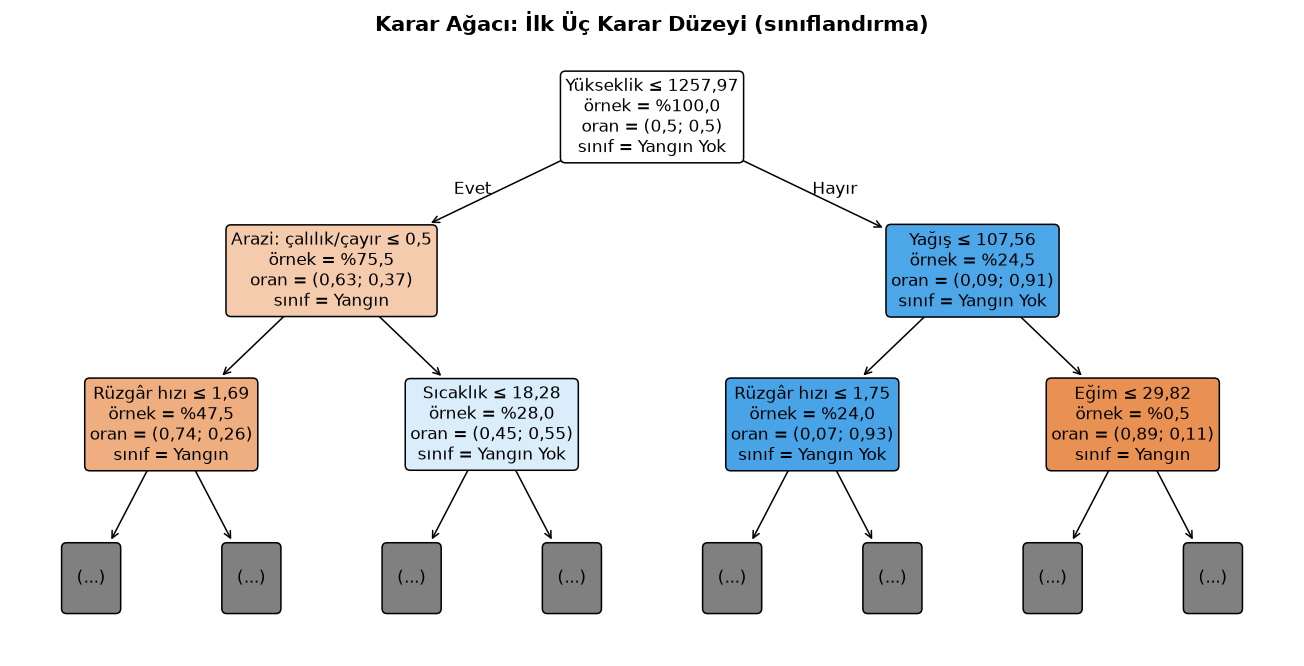

Kök düğüm kuralı: {'ozellik': 'Yukseklik', 'esik': 1257.9739990234375}
Budanmış ağaç: derinlik 16, yaprak 270
Budanmamış ağaç: {'derinlik': 19, 'yaprak': 427, 'test_F1': 0.8710745010559421, 'egitim_F1': 1.0}


In [53]:
kucuk = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42).fit(X_tr, yc_tr)
# Kitapta okunabilmesi için ilk üç karar düzeyi (kök + iki alt düzey) çizilir; daha
# alttaki düğümler "(...)" ile kısaltılır. Ondalıklar iki basamakla gösterilir.
fig, ax = plt.subplots(figsize=(12, 6.2))
yazilar = plot_tree(kucuk, feature_names=[o.OKUNUR[c] for c in o.OZELLIKLER], class_names=list(kucuk.classes_),
                    filled=True, rounded=True, fontsize=11, ax=ax, impurity=False, proportion=True,
                    max_depth=2, precision=2)
# Düğüm yazıları Türkçeleştirilir: örnek payı, sınıf oranları, ondalık virgül.
import re as _re
for y in yazilar:
    t = y.get_text()
    t = t.replace("samples = ", "örnek = %").replace("value = ", "oran = ").replace("class = ", "sınıf = ")
    t = t.replace(" <= ", " ≤ ").replace("≤ -", "≤ −")
    t = _re.sub(r"(\d)\.(\d)", r"\1,\2", t)
    t = _re.sub(r"örnek = %([\d,]+)%", r"örnek = %\1", t)
    t = t.replace("[", "(").replace("]", ")").replace(", ", "; ")
    y.set_text(t)
import matplotlib.text as _mt
for metin in ax.findobj(_mt.Text):
    if metin.get_text().strip() in ("True", "False"):
        metin.set_text("Evet" if metin.get_text().strip() == "True" else "Hayır")
ax.set_title("Karar Ağacı: İlk Üç Karar Düzeyi (sınıflandırma)", fontsize=14)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "dt_agac.png"), bbox_inches="tight")
plt.show()
kok = kucuk.tree_
kok_kural = {"ozellik": o.OZELLIKLER[kok.feature[0]], "esik": float(kok.threshold[0])}
print("Kök düğüm kuralı:", kok_kural)
derin = DecisionTreeClassifier(class_weight='balanced', random_state=42).fit(X_tr, yc_tr)
budanmamis = {"derinlik": int(derin.get_depth()), "yaprak": int(derin.get_n_leaves()),
              "test_F1": o.cls_metrikleri(yc_te, derin.predict(X_te))["F1_macro"],
              "egitim_F1": o.cls_metrikleri(yc_tr, derin.predict(X_tr))["F1_macro"]}
print(f"Budanmış ağaç: derinlik {clf.get_depth()}, yaprak {clf.get_n_leaves()}")
print("Budanmamış ağaç:", budanmamis)

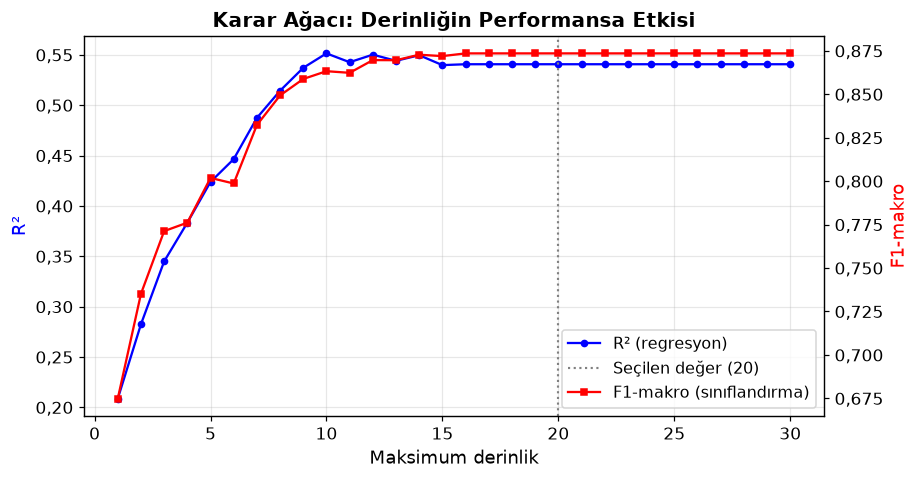

Tarama: [(1, 0.2086, 0.6748), (2, 0.2825, 0.7352), (3, 0.3449, 0.7712), (4, 0.3833, 0.7761), (5, 0.4238, 0.8018), (6, 0.4465, 0.7986), (7, 0.4874, 0.8323), (8, 0.5144, 0.8493), (9, 0.5371, 0.8588), (10, 0.5514, 0.8633), (11, 0.5427, 0.8623), (12, 0.5502, 0.8696), (13, 0.5441, 0.8696), (14, 0.5496, 0.8727), (15, 0.5398, 0.872), (16, 0.5407, 0.8735), (17, 0.5407, 0.8735), (18, 0.5407, 0.8735), (19, 0.5407, 0.8735), (20, 0.5407, 0.8735), (21, 0.5407, 0.8735), (22, 0.5407, 0.8735), (23, 0.5407, 0.8735), (24, 0.5407, 0.8735), (25, 0.5407, 0.8735), (26, 0.5407, 0.8735), (27, 0.5407, 0.8735), (28, 0.5407, 0.8735), (29, 0.5407, 0.8735), (30, 0.5407, 0.8735)]
En yüksek R²: 0.5514 (10) · en yüksek F1-makro: 0.8735 (16)


In [54]:
degerler = list(range(1, 31))
r2_list, f1_list = [], []
for dd in degerler:
    r = DecisionTreeRegressor(max_depth=dd, min_samples_leaf=5, random_state=42).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = DecisionTreeClassifier(max_depth=dd, min_samples_leaf=5, class_weight='balanced',
                               random_state=42).fit(X_tr, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.plot(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(20, color="gray", ls=":", lw=1.4, label="Seçilen değer (20)")
ax1.set_xlabel("Maksimum derinlik")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.plot(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("Karar Ağacı: Derinliğin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "dt_derinlik_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [55]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=42).fit(Xa, yra).predict(Xb)
    c_tahmin = DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, class_weight='balanced', random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² -0.2203 · F1-makro 0.6891


  kat 2: eğitim  4170 · sınama   958 · R² -0.3060 · F1-makro 0.6164
  kat 3: eğitim  4114 · sınama  1014 · R² +0.2690 · F1-makro 0.7917


  kat 4: eğitim  4055 · sınama  1073 · R² +0.2216 · F1-makro 0.7752


  kat 5: eğitim  4150 · sınama   978 · R² +0.2367 · F1-makro 0.7800
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.0402 ± 0.2496
  F1-makro: 0.7305 ± 0.0677


In [56]:
o.sonuc_kaydet("karar_agaci", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp], "agac_derinligi": int(clf.get_depth()), "yaprak_sayisi": int(clf.get_n_leaves()), "max_depth_ayar": 20, "kok_kural": kok_kural, "budanmamis": budanmamis})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\karar_agaci.json


{'algoritma': 'karar_agaci',
 'regresyon': {'MAE': 0.146010388034569,
  'MSE': 0.11479291254983534,
  'RMSE': 0.3388110277866341,
  'R2': 0.5406673691302328,
  'AUC': 0.9028137226497734},
 'siniflandirma': {'Accuracy': 0.8736349453978159,
  'BalancedAcc': 0.8733569169565927,
  'F1_macro': 0.873511806880221,
  'F1_weighted': 0.8735856899907779},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [-0.22028787562065233,
    -0.3060331626555639,
    0.26898114353156943,
    0.22160396334814236,
    0.236730416599789],
   'F1_macro': [0.6890653282869836,
    0.6164432029795158,
    0.7916666666666667,
    0.7751703439395639,
    0.779993692841375],
   'R2_ort': 0.04019889704065691,
   'R2_std': 0.24964124277236938,
   'F1_ort': 0.730467846942821,
   'F1_std': 0.06769373112380253},
  'duyarlilik': {'degerler': [1.0,
    2.0,
    3.0,
    4.0,
    5.0,
    6.0,
    7.0,
    8.0,
    9.0,
    10.0,
    11.0,
    12.0,
    13.0,
    14.0,
    15.0,
    16.0,
    17.0,
    18.0,
    19.0,
    20


---

# BÖLÜM 7 — Rastgele Orman

*Bu bölümün kaynak defteri:* `06_rastgele_orman.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Rastgele orman, çok sayıda karar ağacını farklı bootstrap örneklemleri ve her
bölünmede farklı özellik alt kümeleri üzerinde eğitip sonuçlarını birleştirir
(bagging). Tek ağacın aşırı öğrenme zaafını topluluk gücüyle telafi eder; genellikle
ayar yapılmadan dahi iyi sonuç verir. Ölçekleme gerektirmez ve özellik önemlerini
doğrudan raporlar. Model 200 ağaçla ve yaprak başına en az **1** örnek koşuluyla
(doğrulama kümesiyle seçildi) kurulmuştur.

**Tekrar üretilebilirlik notu.** Orman tek iş parçacığıyla (`n_jobs=1`) çalıştırılır. Paralel
çalıştırmada ağaçların tahminleri iş parçacıklarının bitiş sırasına göre toplanır; toplama sırası
her çalıştırmada değiştiği için son ondalık basamaklarda yuvarlama farkları ve az ağaçlı ormanlarda
eşit oylu sınıfların farklı çözülmesi görülebilir. Tek iş parçacığı her çalıştırmada aynı sonucu verir.

### 1. Veri Hazırlığı

In [57]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [58]:
reg_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=1,
                                  random_state=42, n_jobs=1)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1528
   MSE: 0.0621
  RMSE: 0.2493
    R2: 0.7514
   AUC: 0.9734


In [59]:
o.reg_grafikleri(yr_te, y_pred, "Rastgele Orman", "rastgele_orman")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\rastgele_orman_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [60]:
clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, class_weight='balanced',
                             random_state=42, n_jobs=1)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9243
   BalancedAcc: 0.9245
      F1_macro: 0.9243
   F1_weighted: 0.9243

              precision    recall  f1-score   support

  Yangın Yok      0.934     0.916     0.925       653
      Yangın      0.914     0.933     0.924       629

    accuracy                          0.924      1282
   macro avg      0.924     0.925     0.924      1282
weighted avg      0.925     0.924     0.924      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [61]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1528 |   0.4998 |    0.3931 | -0.2402 (iyi)
     MSE |   0.0621 |   0.2499 |    0.1978 | -0.1357 (iyi)
    RMSE |   0.2493 |   0.4999 |    0.4447 | -0.1955 (iyi)
      R2 |   0.7514 |  -0.0000 |    0.2086 | +0.5428 (iyi)
     AUC |   0.9734 |   0.5000 |    0.6982 | +0.2752 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9243 |   0.5094 |    0.6934 | +0.2309
     BalancedAcc |  0.9245 |   0.5000 |    0.6982 | +0.2263
        F1_macro |  0.9243 |   0.3375 |    0.6748 | +0.2495
     F1_weighted |  0.9243 |   0.3438 |    0.6733 | +0.2510
Tek kural: Yükseklik ≤ 1258.0


In [62]:
o.karmasiklik_grafigi(yc_te, yp, "Rastgele Orman", "rastgele_orman")

Rastgele Orman — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   598     55
      Yangın |    42    587


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\rastgele_orman_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### Özellik Önemleri ve Ağaç Sayısının Etkisi

Özellik önemi, bir değişkenin bölünmelerde sağladığı ortalama saflık (safsızlık
azalması) kazancıdır. Aşağıda önce hangi özelliğin modele ne kadar katkı verdiği
görülür, ardından orman büyüklüğünün (ağaç sayısı) performansı nerede doyurduğu ölçülür.

In [63]:
o.ozellik_onem_grafigi(clf.feature_importances_, "Rastgele Orman", "rastgele_orman")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\rastgele_orman_onem.png'

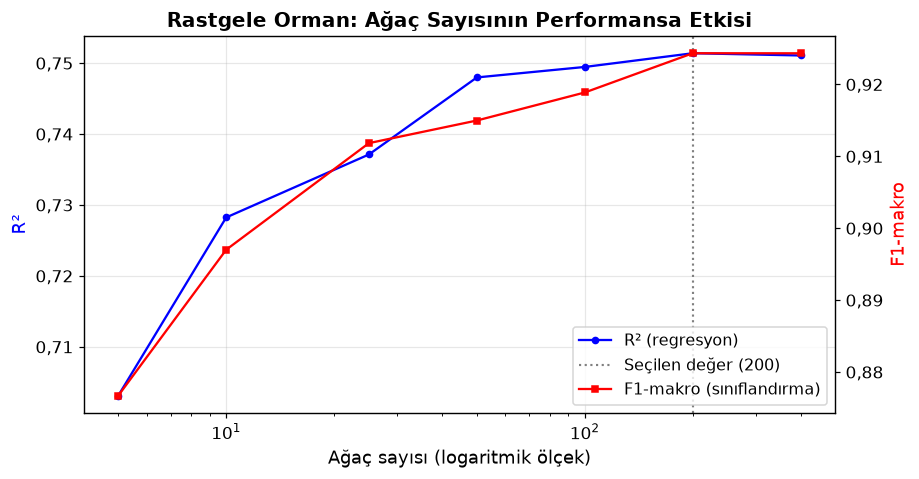

Tarama: [(5, 0.7031, 0.8767), (10, 0.7282, 0.897), (25, 0.7371, 0.9118), (50, 0.748, 0.915), (100, 0.7495, 0.9189), (200, 0.7514, 0.9243), (400, 0.7511, 0.9243)]
En yüksek R²: 0.7514 (200) · en yüksek F1-makro: 0.9243 (200)


In [64]:
degerler = [5, 10, 25, 50, 100, 200, 400]
r2_list, f1_list = [], []
for n in degerler:
    r = RandomForestRegressor(n_estimators=n, min_samples_leaf=1, random_state=42, n_jobs=1).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = RandomForestClassifier(n_estimators=n, min_samples_leaf=1, class_weight='balanced',
                               random_state=42, n_jobs=1).fit(X_tr, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(200, color="gray", ls=":", lw=1.4, label="Seçilen değer (200)")
ax1.set_xlabel("Ağaç sayısı (logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("Rastgele Orman: Ağaç Sayısının Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "rf_nest_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [65]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = RandomForestRegressor(n_estimators=200, min_samples_leaf=1, random_state=42, n_jobs=1).fit(Xa, yra).predict(Xb)
    c_tahmin = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, class_weight='balanced', random_state=42, n_jobs=1).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2068 · F1-makro 0.7744


  kat 2: eğitim  4170 · sınama   958 · R² +0.2194 · F1-makro 0.6322


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5672 · F1-makro 0.8412


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4434 · F1-makro 0.8368


  kat 5: eğitim  4150 · sınama   978 · R² +0.5138 · F1-makro 0.8752
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.3901 ± 0.1499
  F1-makro: 0.7920 ± 0.0862


In [66]:
o.sonuc_kaydet("rastgele_orman", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\rastgele_orman.json


{'algoritma': 'rastgele_orman',
 'regresyon': {'MAE': 0.15281201248049922,
  'MSE': 0.06213102574102965,
  'RMSE': 0.24926095911921234,
  'R2': 0.7513887671429649,
  'AUC': 0.9733710379147728},
 'siniflandirma': {'Accuracy': 0.9243369734789392,
  'BalancedAcc': 0.9245003493719826,
  'F1_macro': 0.9243314025835416,
  'F1_weighted': 0.9243435572644091},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.20675680150012066,
    0.2193687495629676,
    0.5671989518039944,
    0.4433956991068947,
    0.513823860441767],
   'F1_macro': [0.7743649670951473,
    0.6322411273744954,
    0.8412234459000991,
    0.8368137861593001,
    0.8752368404542317],
   'R2_ort': 0.3901088124831489,
   'R2_std': 0.14985056011883277,
   'F1_ort': 0.7919760333966548,
   'F1_std': 0.08624787946512277},
  'duyarlilik': {'degerler': [5.0, 10.0, 25.0, 50.0, 100.0, 200.0, 400.0],
   'R2': [0.7031096784560436,
    0.728235488889484,
    0.7371134833238788,
    0.7479778213309247,
    0.749455718379401,
    0.7513


---

# BÖLÜM 8 — Naive Bayes

*Bu bölümün kaynak defteri:* `07_naive_bayes.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Naive Bayes, Bayes teoremini "özellikler sınıf verildiğinde birbirinden bağımsızdır"
varsayımıyla uygular. GaussianNB sürümü, her özelliğin her sınıf içinde normal
dağıldığını kabul eder. Bu veride iki varsayım da açıkça çiğnenir: sıcaklık ile yükseklik
birbirine sıkı bağlıdır (yükseldikçe hava soğur); uzaklık değişkenleri sağa çarpıktır,
arazi örtüsü göstergeleri ise yalnızca 0 ya da 1 değerini alır. Yöntem yine de hızlıdır,
olasılık üretir ve güçlü bir referans noktası sunar. Yalnızca sınıflandırma yapar.

### 1. Veri Hazırlığı

In [67]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
tb = o.taban_cizgileri(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']


### 2. Model Eğitimi ve Test Performansı

In [68]:
clf = GaussianNB(priors=[0.5, 0.5])   # düzgün önsel — iki sınıfa eşit başlangıç olasılığı
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
olasilik = clf.predict_proba(X_te)[:, list(clf.classes_).index(o.POZITIF)]
auc = o.reg_metrikleri(yr_te, olasilik)["AUC"]
print(f"{'ROC-AUC':>14}: {auc:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))
print("Kullanılan sınıf önselleri (düzgün):")
for et, p in zip(clf.classes_, clf.class_prior_):
    print(f"  {et:>10}: {p:.4f}")

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.7395
   BalancedAcc: 0.7411
      F1_macro: 0.7381
   F1_weighted: 0.7378
       ROC-AUC: 0.8282

              precision    recall  f1-score   support

  Yangın Yok      0.797     0.655     0.719       653
      Yangın      0.698     0.827     0.757       629

    accuracy                          0.739      1282
   macro avg      0.748     0.741     0.738      1282
weighted avg      0.748     0.739     0.738      1282

Kullanılan sınıf önselleri (düzgün):
      Yangın: 0.5000
  Yangın Yok: 0.5000


In [69]:
print("Taban çizgileri")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f} ise Yangın, değilse Yangın Yok")

Taban çizgileri
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.7395 |   0.5094 |    0.6934 | +0.0460
     BalancedAcc |  0.7411 |   0.5000 |    0.6982 | +0.0429
        F1_macro |  0.7381 |   0.3375 |    0.6748 | +0.0633
     F1_weighted |  0.7378 |   0.3438 |    0.6733 | +0.0644
Tek kural: Yükseklik ≤ 1258.0 ise Yangın, değilse Yangın Yok


In [70]:
o.karmasiklik_grafigi(yc_te, yp, "Naive Bayes", "nb")

Naive Bayes — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   428    225
      Yangın |   109    520


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\nb_siniflandirma.png'

### 3. Algoritmaya Özgü Analiz: Sınıf Koşullu Dağılımlar

GaussianNB'nin öğrendiği tek şey, her özellik × sınıf çifti için bir ortalama ve bir
varyanstır. Aşağıdaki eğriler üç özellikte sınıfların ne kadar ayrıştığını gösterir.
Yükseklik ve sıcaklıkta eğriler belirgin biçimde ayrılır; yerleşime uzaklıkta ise
gerçek dağılımın sağa çarpıklığı, Gauss varsayımından ne kadar uzaklaşıldığını gösterir.

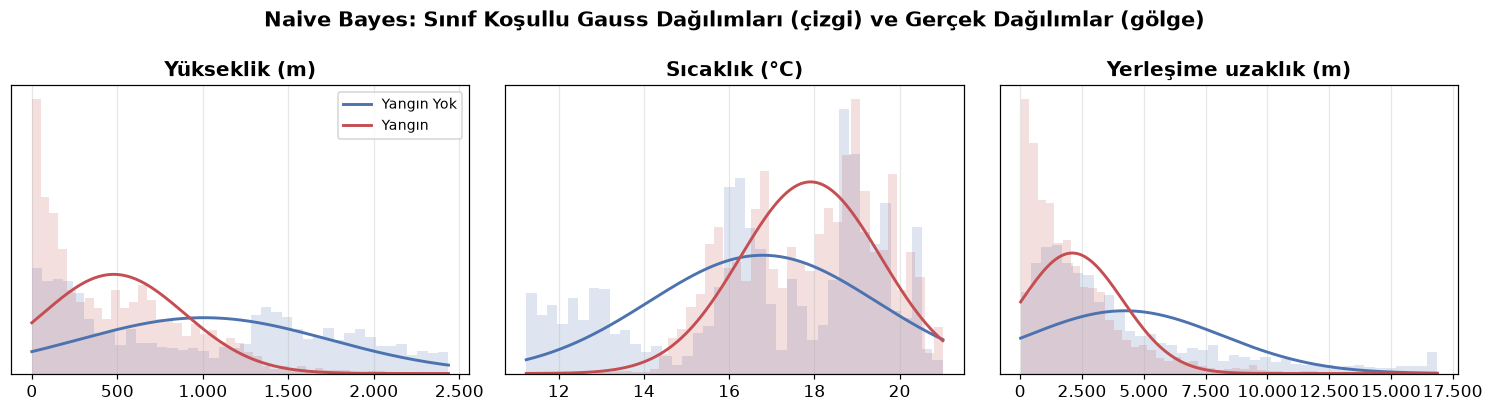

Sınıf ortalamaları (seçili özellikler):
            Yukseklik  Sicaklik  Yerlesim_Uzaklik
Yangın Yok    1005.88     16.79           4230.59
Yangın         478.85     17.91           2107.51

Çarpıklık (eğitim kümesi): {'Yukseklik': 0.77, 'Sicaklik': -0.79, 'Yerlesim_Uzaklik': 1.96}
Yükseklik–sıcaklık korelasyonu: -0.686


In [71]:
GOSTER = ["Yukseklik", "Sicaklik", "Yerlesim_Uzaklik"]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
renk = dict(zip(o.SINIF_ETIKETLERI, ["#4c72b0", "#c44e52"]))
for ax, oz in zip(axes, GOSTER):
    j = o.OZELLIKLER.index(oz)
    alt = float(X_tr[oz].quantile(0.005))
    ust = float(X_tr[oz].quantile(0.995))
    xs = np.linspace(alt, ust, 300)
    for et in o.SINIF_ETIKETLERI:
        i = list(clf.classes_).index(et)
        mu, var = clf.theta_[i, j], clf.var_[i, j]
        ax.hist(X_tr.loc[yc_tr == et, oz].clip(alt, ust), bins=40, density=True,
                color=renk[et], alpha=0.18)
        ax.plot(xs, stats.norm.pdf(xs, mu, np.sqrt(var)), color=renk[et], lw=1.9, label=et)
    ax.set_title(f"{o.OKUNUR[oz]} ({o.BIRIM[oz]})")
    ax.set_yticks([])
axes[0].legend(fontsize=9)
fig.suptitle("Naive Bayes: Sınıf Koşullu Gauss Dağılımları (çizgi) ve Gerçek Dağılımlar (gölge)",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "nb_gauss.png"), bbox_inches="tight")
plt.show()
ort = pd.DataFrame(clf.theta_, index=clf.classes_, columns=o.OZELLIKLER).reindex(o.SINIF_ETIKETLERI)
print("Sınıf ortalamaları (seçili özellikler):")
print(ort[GOSTER].round(2).to_string())
print()
print("Çarpıklık (eğitim kümesi):", {oz: round(float(X_tr[oz].skew()), 2) for oz in GOSTER})
print("Yükseklik–sıcaklık korelasyonu:", round(float(X_tr["Yukseklik"].corr(X_tr["Sicaklik"])), 3))

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [72]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    c_tahmin = GaussianNB(priors=[0.5, 0.5]).fit(Xa, ysa).predict(Xb)
    cv_r2.append(float("nan"))  # bu algoritma regresyon yapmaz
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +nan · F1-makro 0.7186
  kat 2: eğitim  4170 · sınama   958 · R² +nan · F1-makro 0.5478
  kat 3: eğitim  4114 · sınama  1014 · R² +nan · F1-makro 0.7375
  kat 4: eğitim  4055 · sınama  1073 · R² +nan · F1-makro 0.7297


  kat 5: eğitim  4150 · sınama   978 · R² +nan · F1-makro 0.7185
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +nan ± nan
  F1-makro: 0.6904 ± 0.0717


In [73]:
o.sonuc_kaydet("naive_bayes", None, cls,
               ek={"cv": cv_ozet, "tahmin": [str(v) for v in yp], "auc": auc,
                   "sinif_ortalamalari": ort[GOSTER].round(4).to_dict(orient="index"),
                   "carpiklik": {oz: float(X_tr[oz].skew()) for oz in GOSTER},
                   "yukseklik_sicaklik_r": float(X_tr["Yukseklik"].corr(X_tr["Sicaklik"]))})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\naive_bayes.json


{'algoritma': 'naive_bayes',
 'regresyon': None,
 'siniflandirma': {'Accuracy': 0.7394695787831513,
  'BalancedAcc': 0.7410727545850508,
  'F1_macro': 0.7381209252259856,
  'F1_weighted': 0.7377691025588989},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [None, None, None, None, None],
   'F1_macro': [0.7185994624185906,
    0.5477972027972028,
    0.7374854189737912,
    0.7297013224369532,
    0.7184505314148223],
   'R2_ort': None,
   'R2_std': None,
   'F1_ort': 0.690406787608272,
   'F1_std': 0.07166481725126525},
  'tahmin': ['Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Y


---

# BÖLÜM 9 — Gradyan Artırma (GBM)

*Bu bölümün kaynak defteri:* `08_gbm.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Gradyan artırma, karar ağaçlarını **ardışık** olarak kurar: her yeni ağaç, o ana
dek kurulmuş topluluğun hatalarını (kalıntılarını) düzeltmeye çalışır. Bagging'den
(Rastgele Orman) temel farkı budur; ağaçlar bağımsız değil, zincirleme öğrenir. Yüksek
doğruluk verir; buna karşılık eğitimi yavaştır ve öğrenme oranına duyarlıdır. Model
200 ağaç ve **0,3** öğrenme oranıyla (doğrulama kümesiyle seçildi) kurulmuştur.

### 1. Veri Hazırlığı

In [74]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [75]:
reg_model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.3, random_state=42)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1822
   MSE: 0.0685
  RMSE: 0.2618
    R2: 0.7257
   AUC: 0.9728


In [76]:
o.reg_grafikleri(yr_te, y_pred, "Gradyan Artırma (GBM)", "gbm")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\gbm_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [77]:
clf = GradientBoostingClassifier(n_estimators=200, learning_rate=0.3, random_state=42)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9236
   BalancedAcc: 0.9234
      F1_macro: 0.9235
   F1_weighted: 0.9235

              precision    recall  f1-score   support

  Yangın Yok      0.921     0.930     0.925       653
      Yangın      0.926     0.917     0.922       629

    accuracy                          0.924      1282
   macro avg      0.924     0.923     0.924      1282
weighted avg      0.924     0.924     0.924      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [78]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1822 |   0.4998 |    0.3931 | -0.2109 (iyi)
     MSE |   0.0685 |   0.2499 |    0.1978 | -0.1292 (iyi)
    RMSE |   0.2618 |   0.4999 |    0.4447 | -0.1829 (iyi)
      R2 |   0.7257 |  -0.0000 |    0.2086 | +0.5172 (iyi)
     AUC |   0.9728 |   0.5000 |    0.6982 | +0.2746 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9236 |   0.5094 |    0.6934 | +0.2301
     BalancedAcc |  0.9234 |   0.5000 |    0.6982 | +0.2253
        F1_macro |  0.9235 |   0.3375 |    0.6748 | +0.2487
     F1_weighted |  0.9235 |   0.3438 |    0.6733 | +0.2502
Tek kural: Yükseklik ≤ 1258.0


In [79]:
o.karmasiklik_grafigi(yc_te, yp, "Gradyan Artırma (GBM)", "gbm")

Gradyan Artırma (GBM) — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   607     46
      Yangın |    52    577


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\gbm_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### Özellik Önemleri ve Öğrenme Oranının Etkisi

Öğrenme oranı, her ağacın topluluğa yaptığı katkıyı ölçekler. Düşük oran daha yavaş
ama daha güvenli öğrenme demektir; yüksek oran hızlı yakınsar, ancak aşırı öğrenme
riski taşır. Ağaç sayısı 200'de sabit tutularak oran taranmıştır.

In [80]:
o.ozellik_onem_grafigi(clf.feature_importances_, "GBM", "gbm")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\gbm_onem.png'

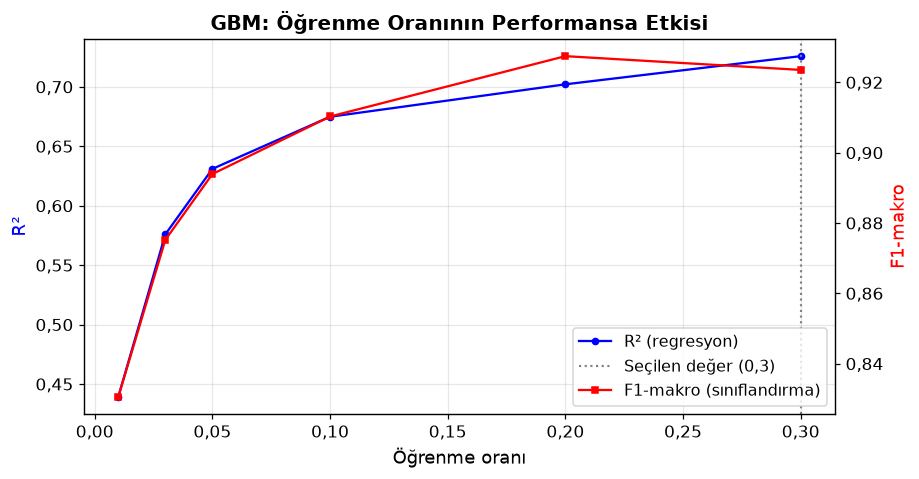

Tarama: [(0.01, 0.4391, 0.8305), (0.03, 0.5759, 0.8752), (0.05, 0.6309, 0.8939), (0.1, 0.6748, 0.9103), (0.2, 0.7021, 0.9274), (0.3, 0.7257, 0.9235)]
En yüksek R²: 0.7257 (0.3) · en yüksek F1-makro: 0.9274 (0.2)


In [81]:
degerler = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3]
r2_list, f1_list = [], []
for lr_ in degerler:
    r = GradientBoostingRegressor(n_estimators=200, learning_rate=lr_, random_state=42).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = GradientBoostingClassifier(n_estimators=200, learning_rate=lr_, random_state=42).fit(X_tr, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.plot(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(0.3, color="gray", ls=":", lw=1.4, label="Seçilen değer (0,3)")
ax1.set_xlabel("Öğrenme oranı")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.plot(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("GBM: Öğrenme Oranının Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "gbm_lr_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [82]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = GradientBoostingRegressor(n_estimators=200, learning_rate=0.3, random_state=42).fit(Xa, yra).predict(Xb)
    c_tahmin = GradientBoostingClassifier(n_estimators=200, learning_rate=0.3, random_state=42).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² -0.0434 · F1-makro 0.7122


  kat 2: eğitim  4170 · sınama   958 · R² -0.0835 · F1-makro 0.6553


  kat 3: eğitim  4114 · sınama  1014 · R² +0.4654 · F1-makro 0.8287


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4001 · F1-makro 0.8488


  kat 5: eğitim  4150 · sınama   978 · R² +0.3655 · F1-makro 0.7950
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.2208 ± 0.2347
  F1-makro: 0.7680 ± 0.0732


In [83]:
o.sonuc_kaydet("gbm", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\gbm.json


{'algoritma': 'gbm',
 'regresyon': {'MAE': 0.18216521586574883,
  'MSE': 0.06854094669105917,
  'RMSE': 0.26180325951190747,
  'R2': 0.7257400943438834,
  'AUC': 0.9728074169115516},
 'siniflandirma': {'Accuracy': 0.9235569422776911,
  'BalancedAcc': 0.9234424948324598,
  'F1_macro': 0.923515058832697,
  'F1_weighted': 0.9235485655886922},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [-0.043426606995056405,
    -0.08347254869021126,
    0.4654498107445434,
    0.40011519852477706,
    0.365524889061288],
   'F1_macro': [0.7121641546526868,
    0.6552732862474744,
    0.8286733981050661,
    0.8487785781396806,
    0.7950072313399987],
   'R2_ort': 0.22083814852906816,
   'R2_std': 0.23467008343081516,
   'F1_ort': 0.7679793296969812,
   'F1_std': 0.07315843348694985},
  'duyarlilik': {'degerler': [0.01, 0.03, 0.05, 0.1, 0.2, 0.3],
   'R2': [0.43911953892437894,
    0.5758622660344483,
    0.6309304396882316,
    0.6747763810362668,
    0.70205232588062,
    0.7257400943438834],
 


---

# BÖLÜM 10 — XGBoost

*Bu bölümün kaynak defteri:* `09_xgboost.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

XGBoost (eXtreme Gradient Boosting), gradyan artırmanın ikinci dereceden
(Newton) adımlar, düzenlileştirme, paralelleştirme ve eksik veri desteğiyle
güçlendirilmiş mühendislik sürümüdür. Veri bilimi yarışmalarında yaygın biçimde öne
çıkmıştır. scikit-learn ile aynı `fit`/`predict` arayüzünü kullanır; tek farkı sınıf
etiketlerinin sayısal olmasını istemesidir. Model 0,1 öğrenme oranı ve **400** artırma
turuyla (doğrulama kümesiyle seçildi) kurulmuştur.

### 1. Veri Hazırlığı

In [84]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
yc_tr_k = o.sinif_kodlari(yc_tr)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [85]:
reg_model = XGBRegressor(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1391
   MSE: 0.0505
  RMSE: 0.2247
    R2: 0.7979
   AUC: 0.9843


In [86]:
o.reg_grafikleri(yr_te, y_pred, "XGBoost", "xgboost")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\xgboost_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [87]:
clf = XGBClassifier(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
clf.fit(X_tr, yc_tr_k)
yp = o.koddan_sinifa(clf.predict(X_te))

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9470
   BalancedAcc: 0.9469
      F1_macro: 0.9469
   F1_weighted: 0.9470

              precision    recall  f1-score   support

  Yangın Yok      0.947     0.949     0.948       653
      Yangın      0.947     0.944     0.946       629

    accuracy                          0.947      1282
   macro avg      0.947     0.947     0.947      1282
weighted avg      0.947     0.947     0.947      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [88]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1391 |   0.4998 |    0.3931 | -0.2539 (iyi)
     MSE |   0.0505 |   0.2499 |    0.1978 | -0.1473 (iyi)
    RMSE |   0.2247 |   0.4999 |    0.4447 | -0.2200 (iyi)
      R2 |   0.7979 |  -0.0000 |    0.2086 | +0.5893 (iyi)
     AUC |   0.9843 |   0.5000 |    0.6982 | +0.2861 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9470 |   0.5094 |    0.6934 | +0.2535
     BalancedAcc |  0.9469 |   0.5000 |    0.6982 | +0.2487
        F1_macro |  0.9469 |   0.3375 |    0.6748 | +0.2721
     F1_weighted |  0.9470 |   0.3438 |    0.6733 | +0.2736
Tek kural: Yükseklik ≤ 1258.0


In [89]:
o.karmasiklik_grafigi(yc_te, yp, "XGBoost", "xgboost")

XGBoost — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   620     33
      Yangın |    35    594


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\xgboost_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### Özellik Önemleri ve Artırma Turu Sayısının Etkisi

`n_estimators`, modele eklenen ağaç sayısıdır; yani artırma turu sayısı. Tur sayısı
arttıkça model karmaşıklaşır, ancak bir noktadan sonra kazanç durur ve aşırı öğrenme
riski yükselir. Önemler, XGBoost'un varsayılan ölçütü olan bölünme kazancına (gain)
göre verilmiştir.

In [90]:
o.ozellik_onem_grafigi(clf.feature_importances_, "XGBoost", "xgboost")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\xgboost_onem.png'

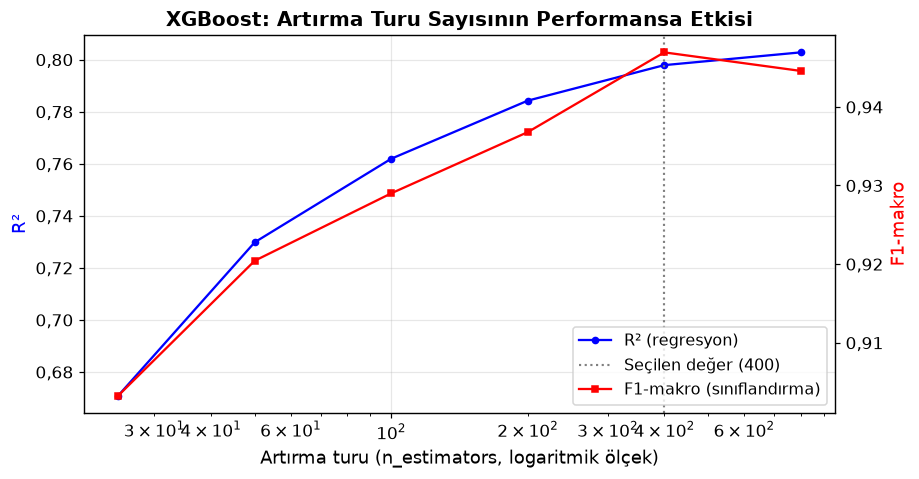

Tarama: [(25, 0.6709, 0.9033), (50, 0.7298, 0.9204), (100, 0.7619, 0.929), (200, 0.7842, 0.9368), (400, 0.7979, 0.9469), (800, 0.8028, 0.9446)]
En yüksek R²: 0.8028 (800) · en yüksek F1-makro: 0.9469 (400)


In [91]:
degerler = [25, 50, 100, 200, 400, 800]
r2_list, f1_list = [], []
for nn in degerler:
    r = XGBRegressor(n_estimators=nn, learning_rate=0.1, random_state=42, verbosity=0).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = XGBClassifier(n_estimators=nn, learning_rate=0.1, random_state=42, verbosity=0).fit(X_tr, yc_tr_k)
    f1_list.append(o.cls_metrikleri(yc_te, o.koddan_sinifa(c.predict(X_te)))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(400, color="gray", ls=":", lw=1.4, label="Seçilen değer (400)")
ax1.set_xlabel("Artırma turu (n_estimators, logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("XGBoost: Artırma Turu Sayısının Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "xgboost_nest_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [92]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = XGBRegressor(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0).fit(Xa, yra).predict(Xb)
    c_tahmin = o.koddan_sinifa(XGBClassifier(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0).fit(Xa, o.sinif_kodlari(ysa)).predict(Xb))
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² -0.0008 · F1-makro 0.7393


  kat 2: eğitim  4170 · sınama   958 · R² +0.0714 · F1-makro 0.6465


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5232 · F1-makro 0.8521


  kat 4: eğitim  4055 · sınama  1073 · R² +0.3657 · F1-makro 0.8389


  kat 5: eğitim  4150 · sınama   978 · R² +0.4491 · F1-makro 0.8301
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.2817 ± 0.2085
  F1-makro: 0.7814 ± 0.0783


In [93]:
o.sonuc_kaydet("xgboost", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\xgboost.json


{'algoritma': 'xgboost',
 'regresyon': {'MAE': 0.1391139829859309,
  'MSE': 0.05051228927229973,
  'RMSE': 0.22474939215112402,
  'R2': 0.7978800066369303,
  'AUC': 0.9843208671242182},
 'siniflandirma': {'Accuracy': 0.9469578783151326,
  'BalancedAcc': 0.9469100665389287,
  'F1_macro': 0.9469360525136836,
  'F1_weighted': 0.9469561994073289},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [-0.0007573383556465085,
    0.07144783846632197,
    0.5232155074839451,
    0.3657061907290744,
    0.44913156934431986],
   'F1_macro': [0.7393304370048557,
    0.6464710938016505,
    0.8521079291247019,
    0.8389147633245586,
    0.830126608768442],
   'R2_ort': 0.28174875353360296,
   'R2_std': 0.20852252558663478,
   'F1_ort': 0.7813901664048417,
   'F1_std': 0.07830389392417739},
  'duyarlilik': {'degerler': [25.0, 50.0, 100.0, 200.0, 400.0, 800.0],
   'R2': [0.6709352611127044,
    0.729844117972045,
    0.7619254873680562,
    0.7842375177817398,
    0.7978800066369303,
    0.802786548


---

# BÖLÜM 11 — CatBoost

*Bu bölümün kaynak defteri:* `10_catboost.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

CatBoost (Yandex), kategorik değişkenleri ön işlemeye gerek kalmadan işleyebilen
ve **ordered boosting** tekniğiyle hedef sızıntısını ve aşırı öğrenmeyi azaltan bir
gradyan artırma kütüphanesidir. Simetrik (oblivious) ağaçlar kullanır ve varsayılan
ayarlarıyla dahi çoğu zaman iyi sonuç vermesiyle tanınır. Model varsayılan 1000 tur ve
**8** ağaç derinliğiyle (doğrulama kümesiyle seçildi) kurulmuştur.

### 1. Veri Hazırlığı

In [94]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
yc_tr_k = o.sinif_kodlari(yc_tr)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [95]:
reg_model = CatBoostRegressor(depth=8, random_state=42, verbose=0)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1408
   MSE: 0.0502
  RMSE: 0.2240
    R2: 0.7992
   AUC: 0.9835


In [96]:
o.reg_grafikleri(yr_te, y_pred, "CatBoost", "catboost")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\catboost_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [97]:
clf = CatBoostClassifier(depth=8, random_state=42, verbose=0)
clf.fit(X_tr, yc_tr_k)
yp = o.koddan_sinifa(clf.predict(X_te))

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9415
   BalancedAcc: 0.9415
      F1_macro: 0.9415
   F1_weighted: 0.9415

              precision    recall  f1-score   support

  Yangın Yok      0.943     0.942     0.943       653
      Yangın      0.940     0.941     0.940       629

    accuracy                          0.941      1282
   macro avg      0.941     0.941     0.941      1282
weighted avg      0.942     0.941     0.941      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [98]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1408 |   0.4998 |    0.3931 | -0.2523 (iyi)
     MSE |   0.0502 |   0.2499 |    0.1978 | -0.1476 (iyi)
    RMSE |   0.2240 |   0.4999 |    0.4447 | -0.2207 (iyi)
      R2 |   0.7992 |  -0.0000 |    0.2086 | +0.5906 (iyi)
     AUC |   0.9835 |   0.5000 |    0.6982 | +0.2853 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9415 |   0.5094 |    0.6934 | +0.2480
     BalancedAcc |  0.9415 |   0.5000 |    0.6982 | +0.2433
        F1_macro |  0.9415 |   0.3375 |    0.6748 | +0.2667
     F1_weighted |  0.9415 |   0.3438 |    0.6733 | +0.2682
Tek kural: Yükseklik ≤ 1258.0


In [99]:
o.karmasiklik_grafigi(yc_te, yp, "CatBoost", "catboost")

CatBoost — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   615     38
      Yangın |    37    592


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\catboost_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### Özellik Önemleri ve Ağaç Derinliğinin Etkisi

Simetrik ağaçta aynı seviyedeki bütün düğümler aynı soruyu sorar; derinlik, modelin
yakalayabileceği özellik etkileşimlerinin karmaşıklığını belirler. Aşırı derinlik
ezberlemeye yol açar. Önemler CatBoost'un varsayılan ölçütü olan tahmin değişimine
(PredictionValuesChange) göre verilmiştir.

In [100]:
o.ozellik_onem_grafigi(clf.feature_importances_, "CatBoost", "catboost")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\catboost_onem.png'

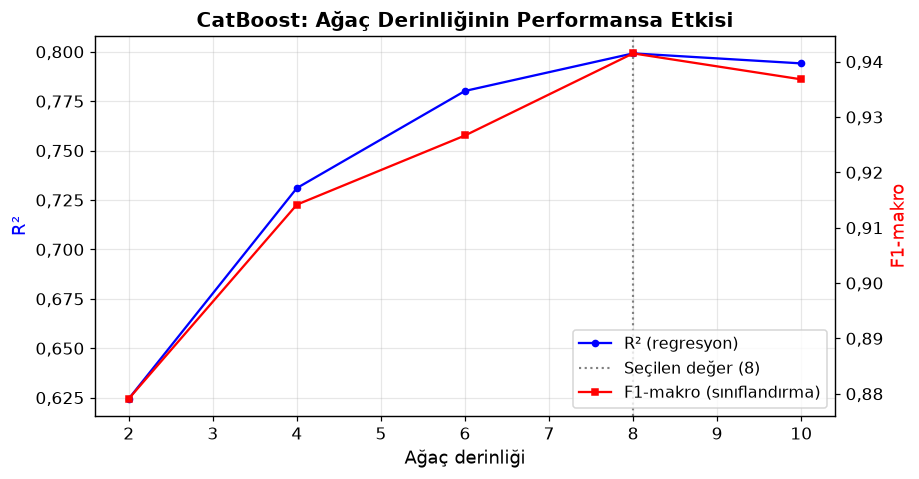

Tarama: [(2, 0.6244, 0.8791), (4, 0.731, 0.9142), (6, 0.7802, 0.9266), (8, 0.7992, 0.9415), (10, 0.7941, 0.9368)]
En yüksek R²: 0.7992 (8) · en yüksek F1-makro: 0.9415 (8)


In [101]:
degerler = [2, 4, 6, 8, 10]
r2_list, f1_list = [], []
for dd in degerler:
    r = CatBoostRegressor(depth=dd, random_state=42, verbose=0).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = CatBoostClassifier(depth=dd, random_state=42, verbose=0).fit(X_tr, yc_tr_k)
    f1_list.append(o.cls_metrikleri(yc_te, o.koddan_sinifa(c.predict(X_te)))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.plot(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(8, color="gray", ls=":", lw=1.4, label="Seçilen değer (8)")
ax1.set_xlabel("Ağaç derinliği")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.plot(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("CatBoost: Ağaç Derinliğinin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "catboost_depth_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [102]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = CatBoostRegressor(depth=8, random_state=42, verbose=0).fit(Xa, yra).predict(Xb)
    c_tahmin = o.koddan_sinifa(CatBoostClassifier(depth=8, random_state=42, verbose=0).fit(Xa, o.sinif_kodlari(ysa)).predict(Xb))
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2909 · F1-makro 0.7728


  kat 2: eğitim  4170 · sınama   958 · R² +0.2198 · F1-makro 0.6690


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5746 · F1-makro 0.8591


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4775 · F1-makro 0.8434


  kat 5: eğitim  4150 · sınama   978 · R² +0.5619 · F1-makro 0.8822
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.4249 ± 0.1442
  F1-makro: 0.8053 ± 0.0773


In [103]:
o.sonuc_kaydet("catboost", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\catboost.json


{'algoritma': 'catboost',
 'regresyon': {'MAE': 0.1407974801432657,
  'MSE': 0.050192582164069174,
  'RMSE': 0.2240370107015115,
  'R2': 0.799159283413426,
  'AUC': 0.9834955214650737},
 'siniflandirma': {'Accuracy': 0.9414976599063962,
  'BalancedAcc': 0.9414917574993245,
  'F1_macro': 0.9414788237334867,
  'F1_weighted': 0.9414984788704358},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.29094921964509823,
    0.21976319719170478,
    0.5746416374847005,
    0.47746502486718767,
    0.5619295654248526],
   'F1_macro': [0.7727903884735083,
    0.6690465223399356,
    0.8590834178250845,
    0.8434473027813087,
    0.8822060676390837],
   'R2_ort': 0.42494972892270877,
   'R2_std': 0.1442127932575188,
   'F1_ort': 0.8053147398117841,
   'F1_std': 0.07731015445838742},
  'duyarlilik': {'degerler': [2.0, 4.0, 6.0, 8.0, 10.0],
   'R2': [0.6244428721183807,
    0.7310240806282102,
    0.7801538170206258,
    0.799159283413426,
    0.7940940778392117],
   'F1_macro': [0.8790945017234


---

# BÖLÜM 12 — LightGBM

*Bu bölümün kaynak defteri:* `11_lightgbm.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

LightGBM (Microsoft), gradyan artırmayı hız ve bellek verimliliği için optimize
eder: histogram tabanlı bölme ve yaprak öncelikli (leaf-wise) ağaç büyütme kullanır.
Büyük veri setlerinde rakiplerinden kat kat hızlıdır; yaprak öncelikli büyüme, küçük
veri setlerinde aşırı öğrenmeye karşı biraz daha hassastır. Model varsayılan 100 tur
ve **127** yaprakla (doğrulama kümesiyle seçildi) kurulmuştur.

### 1. Veri Hazırlığı

In [104]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
yc_tr_k = o.sinif_kodlari(yc_tr)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [105]:
reg_model = LGBMRegressor(num_leaves=127, random_state=42, verbose=-1)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1414
   MSE: 0.0542
  RMSE: 0.2328
    R2: 0.7831
   AUC: 0.9802


In [106]:
o.reg_grafikleri(yr_te, y_pred, "LightGBM", "lightgbm")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\lightgbm_regresyon.png'

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [107]:
clf = LGBMClassifier(num_leaves=127, class_weight='balanced', random_state=42, verbose=-1)
clf.fit(X_tr, yc_tr_k)
yp = o.koddan_sinifa(clf.predict(X_te))

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9415
   BalancedAcc: 0.9414
      F1_macro: 0.9415
   F1_weighted: 0.9415

              precision    recall  f1-score   support

  Yangın Yok      0.938     0.948     0.943       653
      Yangın      0.945     0.935     0.940       629

    accuracy                          0.941      1282
   macro avg      0.942     0.941     0.941      1282
weighted avg      0.942     0.941     0.941      1282



### 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [108]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1414 |   0.4998 |    0.3931 | -0.2517 (iyi)
     MSE |   0.0542 |   0.2499 |    0.1978 | -0.1436 (iyi)
    RMSE |   0.2328 |   0.4999 |    0.4447 | -0.2119 (iyi)
      R2 |   0.7831 |  -0.0000 |    0.2086 | +0.5745 (iyi)
     AUC |   0.9802 |   0.5000 |    0.6982 | +0.2820 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9415 |   0.5094 |    0.6934 | +0.2480
     BalancedAcc |  0.9414 |   0.5000 |    0.6982 | +0.2432
        F1_macro |  0.9415 |   0.3375 |    0.6748 | +0.2667
     F1_weighted |  0.9415 |   0.3438 |    0.6733 | +0.2681
Tek kural: Yükseklik ≤ 1258.0


In [109]:
o.karmasiklik_grafigi(yc_te, yp, "LightGBM", "lightgbm")

LightGBM — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   619     34
      Yangın |    41    588


'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\lightgbm_siniflandirma.png'

### 5. Algoritmaya Özgü Analiz

#### Özellik Önemleri ve Yaprak Sayısının Etkisi

LightGBM yaprak öncelikli büyüdüğü için temel karmaşıklık denetimi `num_leaves`
değeridir. Yaprak sayısı arttıkça model daha ince ayrıntıları yakalar; ancak bu
kolayca ezberlemeye dönüşebilir. Önemler, LightGBM'in varsayılan ölçütü olan bölünme
sayısına (split) göre verilmiştir.

In [110]:
o.ozellik_onem_grafigi(clf.feature_importances_, "LightGBM", "lightgbm")

'C:\\Users\\BALTRON\\AppData\\Local\\Temp\\orman_nb_tjtolrao\\sekiller\\lightgbm_onem.png'

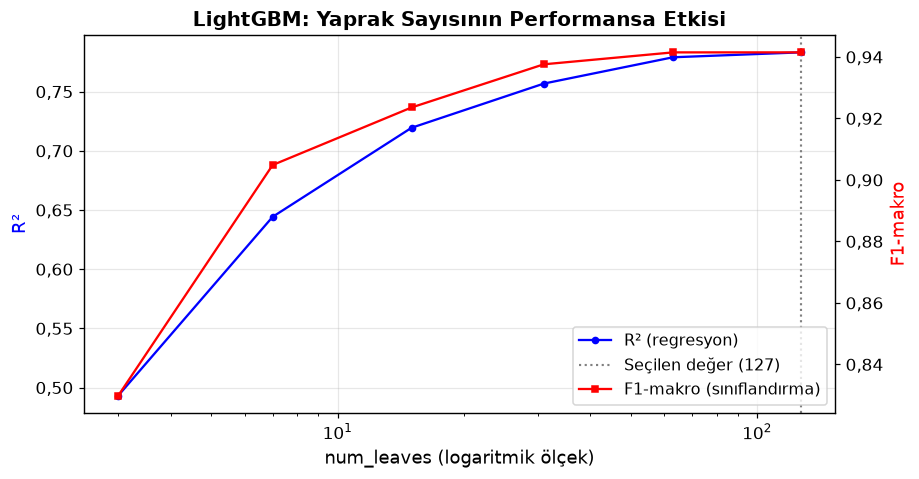

Tarama: [(3, 0.4932, 0.8298), (7, 0.6442, 0.9048), (15, 0.7194, 0.9235), (31, 0.7567, 0.9376), (63, 0.779, 0.9415), (127, 0.7831, 0.9415)]
En yüksek R²: 0.7831 (127) · en yüksek F1-makro: 0.9415 (127)


In [111]:
degerler = [3, 7, 15, 31, 63, 127]
r2_list, f1_list = [], []
for nl_ in degerler:
    r = LGBMRegressor(num_leaves=nl_, random_state=42, verbose=-1).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = LGBMClassifier(num_leaves=nl_, class_weight='balanced', random_state=42, verbose=-1).fit(X_tr, yc_tr_k)
    f1_list.append(o.cls_metrikleri(yc_te, o.koddan_sinifa(c.predict(X_te)))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(127, color="gray", ls=":", lw=1.4, label="Seçilen değer (127)")
ax1.set_xlabel("num_leaves (logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("LightGBM: Yaprak Sayısının Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "lightgbm_leaves_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

### Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [112]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = LGBMRegressor(num_leaves=127, random_state=42, verbose=-1).fit(Xa, yra).predict(Xb)
    c_tahmin = o.koddan_sinifa(LGBMClassifier(num_leaves=127, class_weight='balanced', random_state=42, verbose=-1).fit(Xa, o.sinif_kodlari(ysa)).predict(Xb))
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2616 · F1-makro 0.7647


  kat 2: eğitim  4170 · sınama   958 · R² +0.2020 · F1-makro 0.6741


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5714 · F1-makro 0.8509


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4955 · F1-makro 0.8445


  kat 5: eğitim  4150 · sınama   978 · R² +0.5237 · F1-makro 0.8650
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.4108 ± 0.1494
  F1-makro: 0.7999 ± 0.0720


In [113]:
o.sonuc_kaydet("lightgbm", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\AppData\Local\Temp\orman_nb_tjtolrao\sonuclar\lightgbm.json


{'algoritma': 'lightgbm',
 'regresyon': {'MAE': 0.1413912268250494,
  'MSE': 0.05420080900322541,
  'RMSE': 0.23281067201317343,
  'R2': 0.7831207550909292,
  'AUC': 0.9802014427723823},
 'siniflandirma': {'Accuracy': 0.9414976599063962,
  'BalancedAcc': 0.9413748943971446,
  'F1_macro': 0.9414634324528192,
  'F1_weighted': 0.9414899311265562},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.26158430522889387,
    0.20200076834259773,
    0.5713807615816482,
    0.49552488892014224,
    0.5236697589900075],
   'F1_macro': [0.7646964395696558,
    0.674108532722694,
    0.8509345817444539,
    0.844534015766725,
    0.8650255947003914],
   'R2_ort': 0.41083209661265785,
   'R2_std': 0.14937637553704244,
   'F1_ort': 0.7998598329007841,
   'F1_std': 0.07197338789045074},
  'duyarlilik': {'degerler': [3.0, 7.0, 15.0, 31.0, 63.0, 127.0],
   'R2': [0.4932052287722254,
    0.644211991860522,
    0.7193987290966435,
    0.7567421145784904,
    0.778978060950988,
    0.7831207550909292],


---

# BÖLÜM 13 — Karşılaştırma ve Genel Değerlendirme

*Bu bölümün kaynak defteri:* `12_karsilastirma.ipynb`

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Bu bölüm, önceki on bir notebook'un ürettiği sonuç dosyalarını okur ve tek bir
tabloda birleştirir. Karşılaştırmanın adil olmasının koşulu, bütün modellerin aynı
veri, aynı bölünme ve aynı özelliklerle eğitilmiş olmasıdır; `ortak.py` bu koşulu
güvence altına alır.

Regresyon görevinde (yangın duyarlılık skoru) MAE, MSE (Brier skoru), RMSE, R² (Brier
beceri skoru) ve ROC-AUC; sınıflandırma görevinde doğruluk, dengeli doğruluk, F1-makro
ve F1-ağırlıklı raporlanır. Lojistik Regresyon ile Naive Bayes yalnızca sınıflandırma,
Lineer Regresyon yalnızca regresyon yapar.

**Taban çizgileri hatırlatması:** ortalama ve çoğunluk tabanları hiçbir şey bilmeyen
modeldir; tek kural tabanı (eğitim kümesinden öğrenilmiş tek bir eşik sorusu) ise
geçilmesi gereken asıl çizgidir. Aşağıdaki bütün sayılar bu çizgiler göz önünde
tutularak okunmalıdır.

### 1. Sonuçların Toplanması

In [114]:
import ortak as o
import os
import json
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

df = o.veri_yukle()
tb = o.taban_cizgileri(df)
test = df[~o.egitim_maskesi(df)].reset_index(drop=True)

kayitlar = {}
for yol in sorted(glob.glob(os.path.join(o.SONUC_DIR, "*.json"))):
    ad = os.path.basename(yol)
    if ad.startswith("_"):          # yardımcı dosyalar bir algoritma sonucu değildir
        continue
    with open(yol, encoding="utf-8") as f:
        k = json.load(f)
    kayitlar[k["algoritma"]] = k

GORUNEN_AD = {
    "lojistik_regresyon": "Lojistik Regresyon", "lineer_regresyon": "Lineer Regresyon",
    "knn": "KNN", "svm": "SVM", "karar_agaci": "Karar Ağacı",
    "rastgele_orman": "Rastgele Orman", "naive_bayes": "Naive Bayes",
    "gbm": "GBM", "xgboost": "XGBoost", "catboost": "CatBoost", "lightgbm": "LightGBM",
}
print(f"{len(kayitlar)} algoritmanın sonuç dosyası yüklendi:")
for a in kayitlar:
    print("  -", GORUNEN_AD.get(a, a))
OZET = {}

6410 nokta · yangın 3144 · yangın yok 3266


11 algoritmanın sonuç dosyası yüklendi:
  - CatBoost
  - GBM
  - Karar Ağacı
  - KNN
  - LightGBM
  - Lineer Regresyon
  - Lojistik Regresyon
  - Naive Bayes
  - Rastgele Orman
  - SVM
  - XGBoost


### 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [115]:
satirlar = []
for a, k in kayitlar.items():
    if k["regresyon"]:
        satirlar.append({"Algoritma": GORUNEN_AD[a], **k["regresyon"]})
tablo_reg = pd.DataFrame(satirlar).set_index("Algoritma").sort_values("AUC", ascending=False)
kur = tb["kural_regresyon"]
tablo_reg["Brier_iyilesme_%"] = (kur["MSE"] - tablo_reg["MSE"]) / kur["MSE"] * 100
tabanlar = pd.DataFrame([{"Algoritma": "Taban: tek kural", **kur},
                         {"Algoritma": "Taban: eğitim ortalaması", **tb["regresyon"]}]).set_index("Algoritma")
OZET["regresyon"] = tablo_reg.round(6).reset_index().to_dict(orient="records")
pd.concat([tablo_reg, tabanlar]).round(4)

,MAE,MSE,RMSE,R2,AUC,Brier_iyilesme_%
Algoritma,,,,,,
XGBoost,0.1391,0.0505,0.2247,0.7979,0.9843,74.4613
CatBoost,0.1408,0.0502,0.2240,0.7992,0.9835,74.6229
LightGBM,0.1414,0.0542,0.2328,0.7831,0.9802,72.5964
Rastgele Orman,0.1528,0.0621,0.2493,0.7514,0.9734,68.5869
GBM,0.1822,0.0685,0.2618,0.7257,0.9728,65.3461
SVM,0.2274,0.1136,0.3370,0.5455,0.9180,42.5779
KNN,0.2368,0.1190,0.3450,0.5237,0.9077,39.8177
Karar Ağacı,0.1460,0.1148,0.3388,0.5407,0.9028,41.9614
Lineer Regresyon,0.3568,0.1714,0.4140,0.3142,0.8288,13.3445


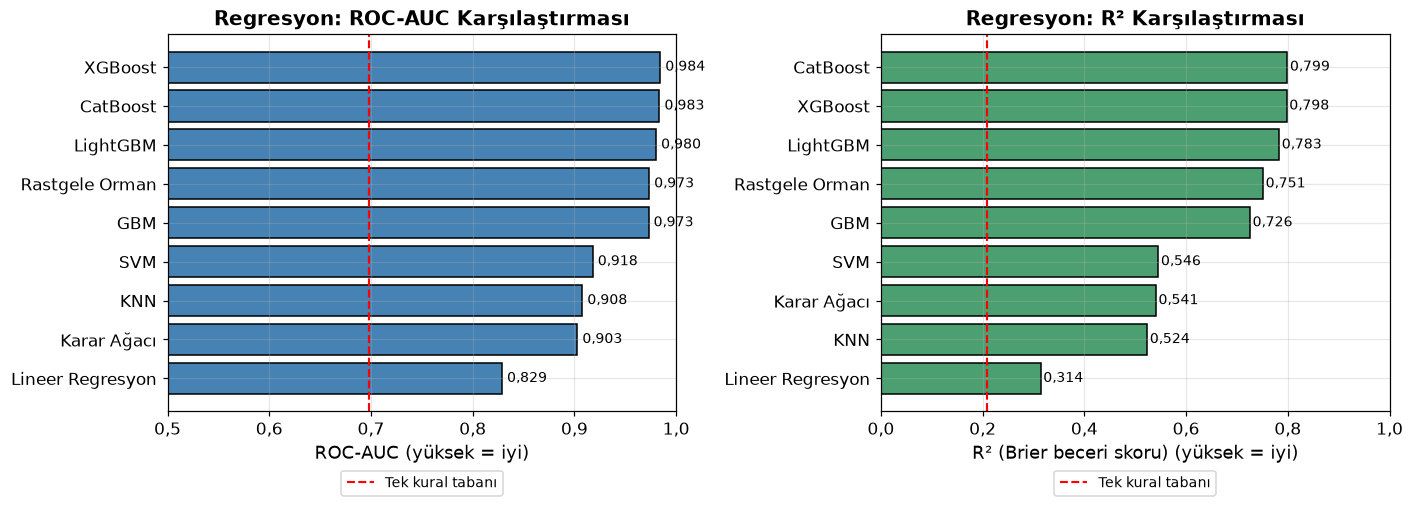

En yüksek AUC: XGBoost (0.9843); tek kural 0.6982
Tek kurala göre Brier iyileşmesi (%):
Algoritma
XGBoost             74.5
CatBoost            74.6
LightGBM            72.6
Rastgele Orman      68.6
GBM                 65.3
SVM                 42.6
KNN                 39.8
Karar Ağacı         42.0
Lineer Regresyon    13.3


In [116]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, olcut, ad, renk, alt in ((axes[0], "AUC", "ROC-AUC", "steelblue", 0.5),
                                 (axes[1], "R2", "R² (Brier beceri skoru)", "#4c9f70", 0.0)):
    t = tablo_reg.sort_values(olcut)
    ax.barh(t.index, t[olcut].clip(lower=alt), color=renk, edgecolor="k")
    ax.axvline(kur[olcut], color="red", ls="--", lw=1.4, label="Tek kural tabanı")
    ax.set_xlabel(f"{ad} (yüksek = iyi)")
    ax.set_title(f"Regresyon: {ad.split(' (')[0]} Karşılaştırması")
    ax.set_xlim(alt, 1)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=9)
    for i, v in enumerate(t[olcut]):
        ax.text(max(v, alt) + 0.005, i, o.sayi(v, 3), va="center", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_regresyon.png"), bbox_inches="tight")
plt.show()

en_iyi_reg = tablo_reg.index[0]
print(f"En yüksek AUC: {en_iyi_reg} ({tablo_reg['AUC'].iloc[0]:.4f}); tek kural {kur['AUC']:.4f}")
print("Tek kurala göre Brier iyileşmesi (%):")
print(tablo_reg["Brier_iyilesme_%"].round(1).to_string())

#### 2.1 ROC Eğrileri

ROC eğrisi, skor eşiği 1'den 0'a indirildikçe yakalanan yangın noktalarının oranını
(duyarlılık, dikey eksen) yanlış alarm oranına (yatay eksen) karşı çizer. Eğri sol üst
köşeye ne kadar yakınsa skor o kadar iyidir; eğrinin altındaki alan AUC'dir. Köşegen
rastgele sıralamayı gösterir.

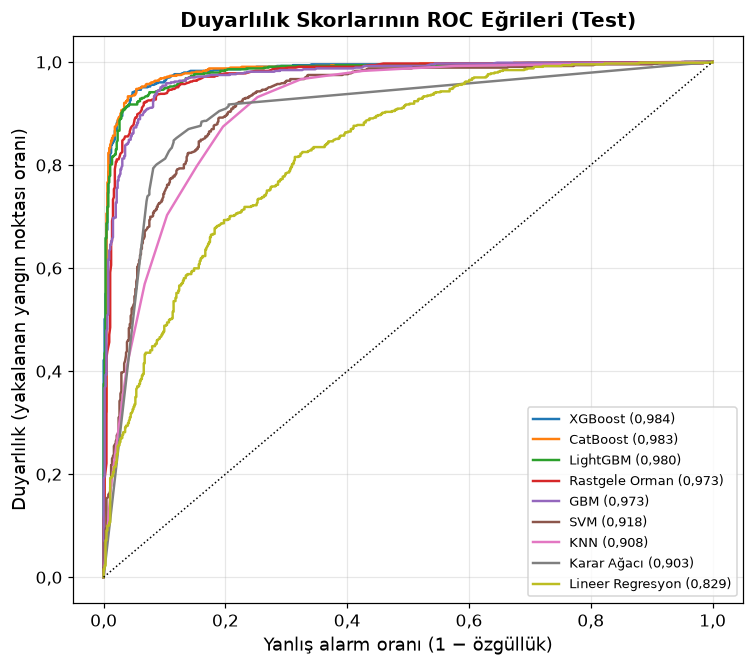

Yanlış alarm oranı %10 iken yakalanan yangın noktası oranı:
CatBoost            0.970
XGBoost             0.963
GBM                 0.954
LightGBM            0.949
Rastgele Orman      0.938
Karar Ağacı         0.812
SVM                 0.748
KNN                 0.688
Lineer Regresyon    0.488


In [117]:
fig, ax = plt.subplots(figsize=(7, 6.2))
gercek = test[o.HEDEF].values
roc_ozet = {}
for ad in tablo_reg.index:
    kod = {v: k for k, v in GORUNEN_AD.items()}[ad]
    skor = np.array(kayitlar[kod]["ek"].get("tahmin_reg") or kayitlar[kod]["ek"]["tahmin"], dtype=float)
    fpr, tpr, _ = roc_curve(gercek, skor)
    ax.plot(fpr, tpr, lw=1.6, label=f"{ad} ({o.sayi(tablo_reg.loc[ad, 'AUC'], 3)})")
    roc_ozet[ad] = float(np.interp(0.10, fpr, tpr))
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set_xlabel("Yanlış alarm oranı (1 − özgüllük)")
ax.set_ylabel("Duyarlılık (yakalanan yangın noktası oranı)")
ax.set_title("Duyarlılık Skorlarının ROC Eğrileri (Test)")
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_roc.png"), bbox_inches="tight")
plt.show()
OZET["roc_tpr_at_fpr10"] = roc_ozet
print("Yanlış alarm oranı %10 iken yakalanan yangın noktası oranı:")
print(pd.Series(roc_ozet).sort_values(ascending=False).round(3).to_string())

### 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [118]:
satirlar = []
for a, k in kayitlar.items():
    if k["siniflandirma"]:
        satirlar.append({"Algoritma": GORUNEN_AD[a], **k["siniflandirma"]})
tablo_cls = pd.DataFrame(satirlar).set_index("Algoritma").sort_values("F1_macro", ascending=False)
kurc = tb["kural_siniflandirma"]
tabanlar = pd.DataFrame([{"Algoritma": "Taban: tek kural", **kurc},
                         {"Algoritma": "Taban: çoğunluk sınıfı", **tb["siniflandirma"]}]).set_index("Algoritma")
OZET["siniflandirma"] = tablo_cls.round(6).reset_index().to_dict(orient="records")
pd.concat([tablo_cls, tabanlar]).round(4)

,Accuracy,BalancedAcc,F1_macro,F1_weighted
Algoritma,,,,
XGBoost,0.9470,0.9469,0.9469,0.9470
CatBoost,0.9415,0.9415,0.9415,0.9415
LightGBM,0.9415,0.9414,0.9415,0.9415
Rastgele Orman,0.9243,0.9245,0.9243,0.9243
GBM,0.9236,0.9234,0.9235,0.9235
Karar Ağacı,0.8736,0.8734,0.8735,0.8736
KNN,0.8385,0.8392,0.8385,0.8384
SVM,0.8362,0.8368,0.8362,0.8361
Naive Bayes,0.7395,0.7411,0.7381,0.7378


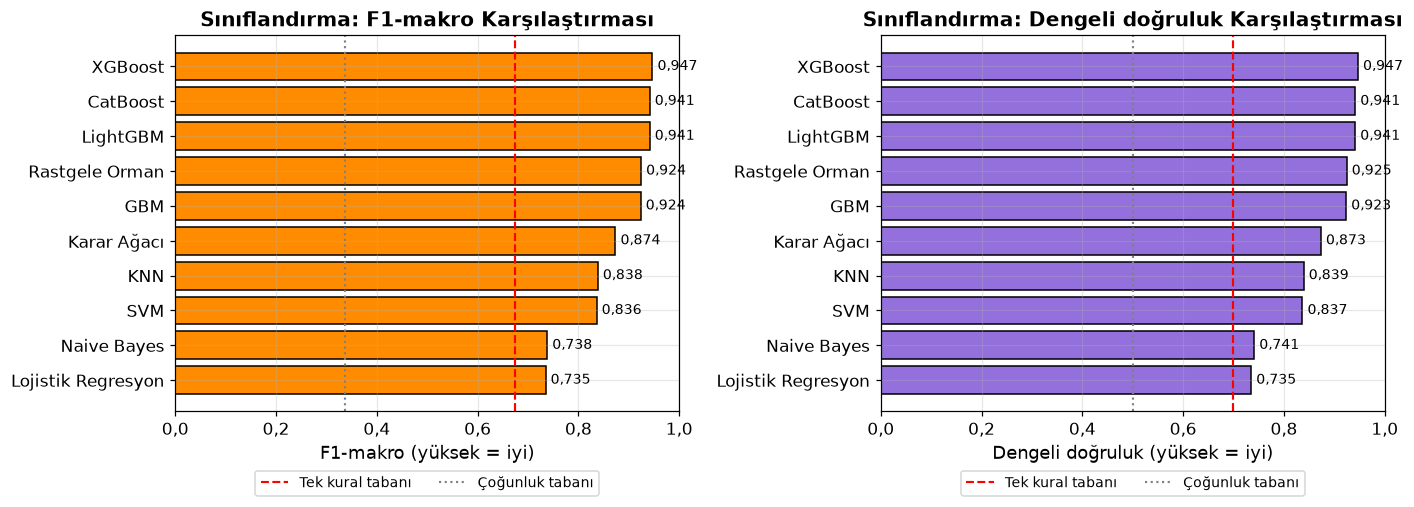

En yüksek F1-makro: XGBoost (0.9469); tek kural 0.6748


In [119]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, olcut, ad, renk in ((axes[0], "F1_macro", "F1-makro", "darkorange"),
                            (axes[1], "BalancedAcc", "Dengeli doğruluk", "mediumpurple")):
    t = tablo_cls.sort_values(olcut)
    ax.barh(t.index, t[olcut], color=renk, edgecolor="k")
    ax.axvline(kurc[olcut], color="red", ls="--", lw=1.4, label="Tek kural tabanı")
    ax.axvline(tb["siniflandirma"][olcut], color="gray", ls=":", lw=1.4, label="Çoğunluk tabanı")
    ax.set_xlim(0, 1)
    ax.set_xlabel(f"{ad} (yüksek = iyi)")
    ax.set_title(f"Sınıflandırma: {ad} Karşılaştırması")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
    for i, v in enumerate(t[olcut]):
        ax.text(v + 0.01, i, o.sayi(v, 3), va="center", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_siniflandirma.png"), bbox_inches="tight")
plt.show()
en_iyi_cls = tablo_cls.index[0]
print(f"En yüksek F1-makro: {en_iyi_cls} ({tablo_cls['F1_macro'].iloc[0]:.4f}); tek kural {kurc['F1_macro']:.4f}")

### 4. Yangın Noktalarının Yakalanması

Uygulamada en çok önemsenen soru, yangın noktalarının ne kadarının "Yangın" olarak
işaretlendiği ve bu işaretlerin ne kadar güvenilir olduğudur. Aşağıda her model için
Yangın sınıfının **duyarlılığı** (gerçek yangın noktalarının kaçta kaçı yakalandı) ve
**kesinliği** (Yangın dendiğinde kaçta kaçı gerçekten yangın noktasıydı) verilir. Tek
kural tabanı da aynı ölçütlerle hesaplanmıştır.

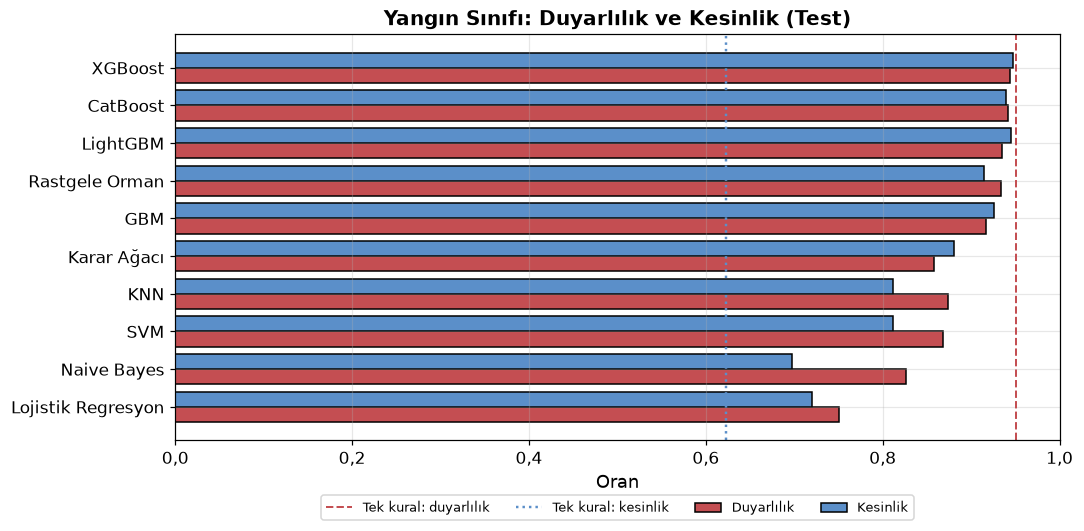

Test kümesindeki yangın noktası: 629
Tek kural: {'Duyarlılık': 0.9507, 'Kesinlik': 0.6229, 'F1': 0.7527}


,Duyarlılık,Kesinlik,F1
Algoritma,,,
XGBoost,0.9444,0.9474,0.9459
CatBoost,0.9412,0.9397,0.9404
LightGBM,0.9348,0.9453,0.9400
Rastgele Orman,0.9332,0.9143,0.9237
GBM,0.9173,0.9262,0.9217
Karar Ağacı,0.8585,0.8809,0.8696
KNN,0.8744,0.8112,0.8416
SVM,0.8680,0.8113,0.8387
Naive Bayes,0.8267,0.6980,0.7569


In [120]:
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
gercek = test["Sinif"].astype(str).values == o.POZITIF
yakalama = []
for a, k in kayitlar.items():
    if not k["siniflandirma"]:
        continue
    tah = np.array(k["ek"].get("tahmin_sinif") or k["ek"]["tahmin"]) == o.POZITIF
    yakalama.append({"Algoritma": GORUNEN_AD[a], "Duyarlılık": recall_score(gercek, tah),
                     "Kesinlik": precision_score(gercek, tah), "F1": f1_score(gercek, tah)})
X_tr, X_te, _, _, yc_tr, _ = o.bolunme(df)
kutuk = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_tr, np.asarray(yc_tr, dtype=object))
kur_tah = kutuk.predict(X_te) == o.POZITIF
yakalama_kur = {"Duyarlılık": recall_score(gercek, kur_tah), "Kesinlik": precision_score(gercek, kur_tah),
                "F1": f1_score(gercek, kur_tah)}
tablo_yak = pd.DataFrame(yakalama).set_index("Algoritma").sort_values("F1", ascending=False)
OZET["yakalama"] = tablo_yak.round(6).reset_index().to_dict(orient="records")
OZET["yakalama_kural"] = yakalama_kur
OZET["yangin_test"] = int(gercek.sum())

fig, ax = plt.subplots(figsize=(10, 5))
t = tablo_yak.sort_values("F1")
y = np.arange(len(t)); w = 0.4
ax.barh(y - w / 2, t["Duyarlılık"], w, color="#c44e52", edgecolor="k", label="Duyarlılık")
ax.barh(y + w / 2, t["Kesinlik"], w, color="#5b8fc9", edgecolor="k", label="Kesinlik")
ax.axvline(yakalama_kur["Duyarlılık"], color="#c44e52", ls="--", lw=1.3, label="Tek kural: duyarlılık")
ax.axvline(yakalama_kur["Kesinlik"], color="#5b8fc9", ls=":", lw=1.6, label="Tek kural: kesinlik")
ax.set_yticks(y); ax.set_yticklabels(t.index)
ax.set_xlim(0, 1)
ax.set_xlabel("Oran")
ax.set_title("Yangın Sınıfı: Duyarlılık ve Kesinlik (Test)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_yakalama.png"), bbox_inches="tight")
plt.show()
print(f"Test kümesindeki yangın noktası: {int(gercek.sum())}")
print("Tek kural:", {k: round(v, 4) for k, v in yakalama_kur.items()})
tablo_yak.round(4)

### 5. İki Görevin Birlikte Değerlendirilmesi

Her iki görevi de yerine getiren sekiz algoritmanın performansı 0–1 aralığında
normalleştirilmiştir (yüksek = iyi). Bu profil, algoritmaların birbirine göre konumunu
gösterir; normalleştirme yalnızca bu sekiz model arasında yapıldığından mutlak bir
başarı ölçüsü değildir.

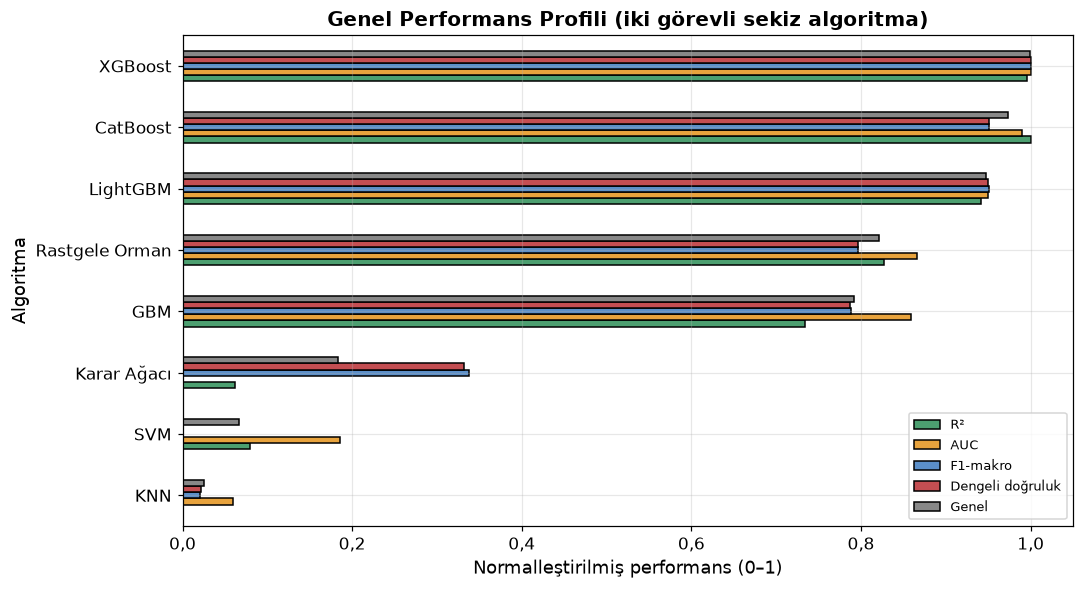

,R²,AUC,F1-makro,Dengeli doğruluk,Genel
Algoritma,,,,,
XGBoost,0.995,1.000,1.000,1.000,0.999
CatBoost,1.000,0.990,0.951,0.951,0.973
LightGBM,0.942,0.949,0.951,0.950,0.948
Rastgele Orman,0.827,0.866,0.796,0.797,0.821
GBM,0.733,0.859,0.789,0.787,0.792
Karar Ağacı,0.062,0.000,0.337,0.332,0.183
SVM,0.079,0.186,0.000,0.000,0.066
KNN,0.000,0.060,0.021,0.022,0.026


In [121]:
ortak_algo = [a for a, k in kayitlar.items() if k["regresyon"] and k["siniflandirma"]]
ozet = pd.DataFrame({
    "Algoritma": [GORUNEN_AD[a] for a in ortak_algo],
    "R2": [kayitlar[a]["regresyon"]["R2"] for a in ortak_algo],
    "AUC": [kayitlar[a]["regresyon"]["AUC"] for a in ortak_algo],
    "F1_macro": [kayitlar[a]["siniflandirma"]["F1_macro"] for a in ortak_algo],
    "BalancedAcc": [kayitlar[a]["siniflandirma"]["BalancedAcc"] for a in ortak_algo],
}).set_index("Algoritma")

def olcekle(s, ters=False):
    n = (s - s.min()) / (s.max() - s.min())
    return 1 - n if ters else n

norm = pd.DataFrame(index=ozet.index)
norm["R²"] = olcekle(ozet["R2"])
norm["AUC"] = olcekle(ozet["AUC"])
norm["F1-makro"] = olcekle(ozet["F1_macro"])
norm["Dengeli doğruluk"] = olcekle(ozet["BalancedAcc"])
norm["Genel"] = norm.mean(axis=1)
norm = norm.sort_values("Genel", ascending=False)
OZET["genel_profil"] = norm.round(6).reset_index().to_dict(orient="records")

ax = norm.sort_values("Genel").plot.barh(
    figsize=(10, 5.5), edgecolor="k",
    color=["#4c9f70", "#e8a33d", "#5b8fc9", "#c44e52", "#888888"])
ax.set_xlabel("Normalleştirilmiş performans (0–1)")
ax.set_title("Genel Performans Profili (iki görevli sekiz algoritma)")
ax.legend(loc="lower right", fontsize=8.5)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_genel.png"), bbox_inches="tight")
plt.show()
norm.round(3)

### 6. Güvenilirlik: Rastgele Test ve Sözde Mekânsal Doğrulama

Her algoritmanın sözde mekânsal grup doğrulamasında (eğitim kümesi, 5 kat; her katta
bazı iklim grupları bütünüyle dışarıda) elde ettiği değerlerin ortalaması ve standart
sapması, rastgele test kümesindeki değerle yan yana verilir. Aradaki fark **iyimserlik
payıdır**: rastgele bölünmenin, modelin hiç görmediği bir bölgedeki başarısını ne kadar
abarttığını gösterir. Büyük standart sapma, başarının bölgeden bölgeye değiştiğini gösterir.

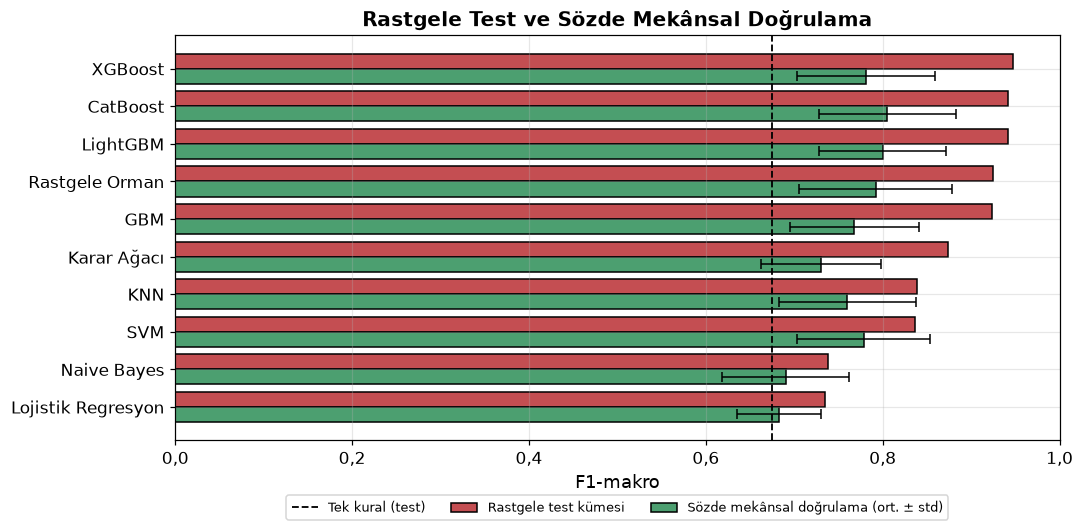

,R2_ort,R2_std,F1_ort,F1_std,Test_R2,Test_F1,F1_fark,R2_fark
Algoritma,,,,,,,,
CatBoost,0.4249,0.1442,0.8053,0.0773,0.7992,0.9415,0.1362,0.3742
GBM,0.2208,0.2347,0.7680,0.0732,0.7257,0.9235,0.1555,0.5049
Karar Ağacı,0.0402,0.2496,0.7305,0.0677,0.5407,0.8735,0.1430,0.5005
KNN,0.3449,0.1332,0.7602,0.0779,0.5237,0.8385,0.0783,0.1789
LightGBM,0.4108,0.1494,0.7999,0.0720,0.7831,0.9415,0.1416,0.3723
Lineer Regresyon,0.2126,0.0917,NaN,NaN,0.3142,NaN,NaN,0.1016
Lojistik Regresyon,NaN,NaN,0.6826,0.0476,NaN,0.7348,0.0522,NaN
Naive Bayes,NaN,NaN,0.6904,0.0717,NaN,0.7381,0.0477,NaN
Rastgele Orman,0.3901,0.1499,0.7920,0.0862,0.7514,0.9243,0.1324,0.3613


In [122]:
cvs = []
for a, k in kayitlar.items():
    cv = k["ek"]["cv"]
    cvs.append({"Algoritma": GORUNEN_AD[a], "R2_ort": cv["R2_ort"], "R2_std": cv["R2_std"],
                "F1_ort": cv["F1_ort"], "F1_std": cv["F1_std"],
                "Test_R2": k["regresyon"]["R2"] if k["regresyon"] else None,
                "Test_F1": k["siniflandirma"]["F1_macro"] if k["siniflandirma"] else None})
tablo_cv = pd.DataFrame(cvs).set_index("Algoritma")
tablo_cv["F1_fark"] = tablo_cv["Test_F1"] - tablo_cv["F1_ort"]
tablo_cv["R2_fark"] = tablo_cv["Test_R2"] - tablo_cv["R2_ort"]
OZET["cv"] = tablo_cv.reset_index().to_dict(orient="records")

t = tablo_cv.dropna(subset=["Test_F1"]).sort_values("Test_F1")
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(t)); w = 0.4
ax.barh(y + w / 2, t["Test_F1"], w, color="#c44e52", edgecolor="k", label="Rastgele test kümesi")
ax.barh(y - w / 2, t["F1_ort"], w, xerr=t["F1_std"], color="#4c9f70", edgecolor="k",
        error_kw={"elinewidth": 1, "capsize": 3}, label="Sözde mekânsal doğrulama (ort. ± std)")
ax.axvline(tb["kural_siniflandirma"]["F1_macro"], color="k", ls="--", lw=1.2, label="Tek kural (test)")
ax.set_yticks(y); ax.set_yticklabels(t.index)
ax.set_xlim(0, 1)
ax.set_xlabel("F1-makro")
ax.set_title("Rastgele Test ve Sözde Mekânsal Doğrulama")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_cv.png"), bbox_inches="tight")
plt.show()
tablo_cv.round(4)

### 7. Hata Analizi: En İyi Regresyon Modeli Nerede Yanılıyor?

En yüksek AUC değerine ulaşan modelin mutlak hatası (|gerçek − skor|), tek kural
tabanıyla arazi örtüsü sınıflarına ve iklim gruplarına göre karşılaştırılır. Böylece
modelin kazancının hangi arazi türlerinde ve hangi bölgelerde yoğunlaştığı görülür.

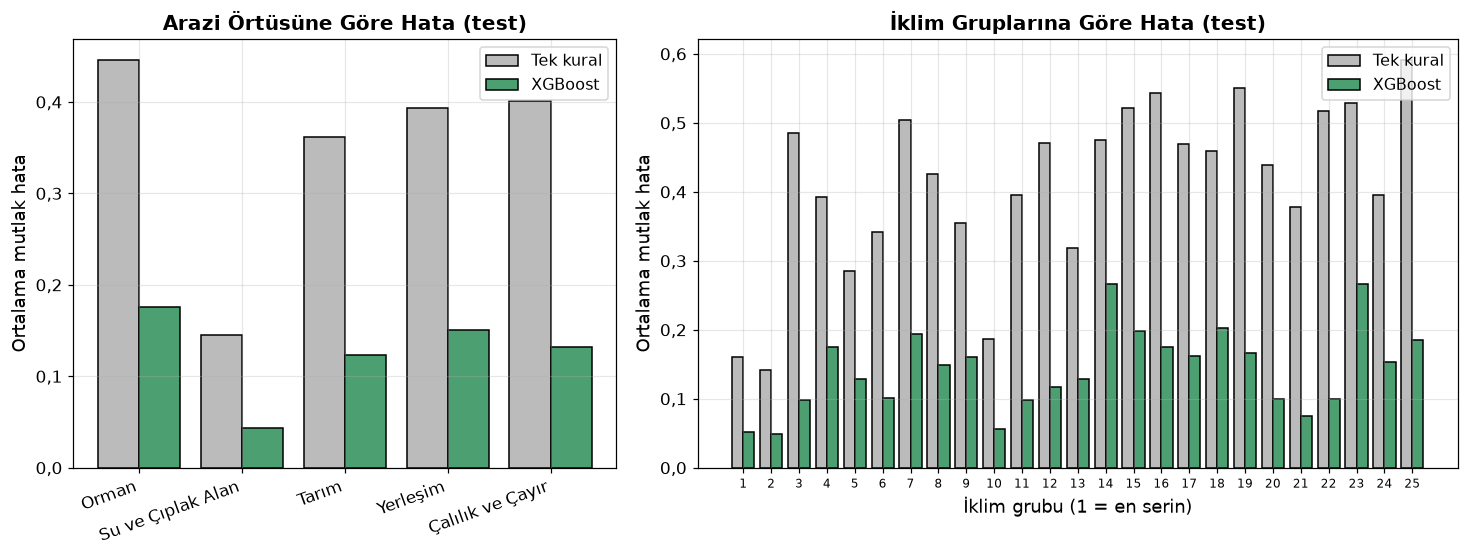

Arazi örtüsüne göre MAE:
                   hata_model  hata_kural  nokta
Arazi                                           
Orman                   0.175       0.446    382
Su ve Çıplak Alan       0.044       0.145     64
Tarım                   0.124       0.362    282
Yerleşim                0.150       0.393     28
Çalılık ve Çayır        0.132       0.401    526

Sınıflara göre MAE:
            hata_model  hata_kural
Sinif                             
Yangın Yok       0.120       0.382
Yangın           0.159       0.404

İklim grubu bazında iyileşme (%):
Iklim_Grubu
1     67.7
2     65.8
3     79.9
4     55.4
5     55.0
6     70.3
7     61.6
8     65.0
9     54.7
10    70.0
11    75.2
12    75.2
13    59.3
14    44.0
15    62.0
16    67.8
17    65.4
18    56.1
19    69.8
20    77.2
21    80.0
22    80.7
23    49.6
24    61.2
25    68.8


In [123]:
ad_kod = {v: k for k, v in GORUNEN_AD.items()}[en_iyi_reg]
test["tahmin"] = np.array(kayitlar[ad_kod]["ek"].get("tahmin_reg") or kayitlar[ad_kod]["ek"]["tahmin"])
from sklearn.tree import DecisionTreeRegressor
X_tr, X_te, yr_tr, _, _, _ = o.bolunme(df)
test["kural"] = DecisionTreeRegressor(max_depth=1, random_state=42).fit(X_tr, yr_tr).predict(X_te)
test["hata_model"] = (test[o.HEDEF] - test["tahmin"]).abs()
test["hata_kural"] = (test[o.HEDEF] - test["kural"]).abs()
arazi = test.groupby("Arazi")[["hata_model", "hata_kural"]].mean()
arazi["nokta"] = test.groupby("Arazi").size()
grup = test.groupby(o.GRUP)[["hata_model", "hata_kural"]].mean()
grup["iyilesme_%"] = (grup["hata_kural"] - grup["hata_model"]) / grup["hata_kural"] * 100
sinif_mae = test.groupby("Sinif", observed=False)[["hata_model", "hata_kural"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1, 1.4]})
x = np.arange(len(arazi)); w = 0.4
axes[0].bar(x - w / 2, arazi["hata_kural"], w, color="#bbbbbb", edgecolor="k", label="Tek kural")
axes[0].bar(x + w / 2, arazi["hata_model"], w, color="#4c9f70", edgecolor="k", label=en_iyi_reg)
axes[0].set_xticks(x); axes[0].set_xticklabels(arazi.index, rotation=20, ha="right")
axes[0].set_ylabel("Ortalama mutlak hata")
axes[0].set_title("Arazi Örtüsüne Göre Hata (test)")
axes[0].legend()
x = np.arange(len(grup))
axes[1].bar(x - w / 2, grup["hata_kural"], w, color="#bbbbbb", edgecolor="k", label="Tek kural")
axes[1].bar(x + w / 2, grup["hata_model"], w, color="#4c9f70", edgecolor="k", label=en_iyi_reg)
axes[1].set_xticks(x); axes[1].set_xticklabels(grup.index.astype(str), fontsize=8)
axes[1].set_xlabel("İklim grubu (1 = en serin)")
axes[1].set_ylabel("Ortalama mutlak hata")
axes[1].set_title("İklim Gruplarına Göre Hata (test)")
axes[1].legend(loc="upper right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "karsilastirma_hata_analizi.png"), bbox_inches="tight")
plt.show()

OZET["hata_analizi"] = {
    "model": en_iyi_reg,
    "arazi": {i: {"model": float(r.hata_model), "kural": float(r.hata_kural), "nokta": int(r.nokta)}
              for i, r in arazi.iterrows()},
    "grup": {int(i): {"model": float(r.hata_model), "kural": float(r.hata_kural),
                      "iyilesme_%": float(r["iyilesme_%"])} for i, r in grup.iterrows()},
    "sinif": {str(s): {"model": float(r.hata_model), "kural": float(r.hata_kural)}
              for s, r in sinif_mae.iterrows()},
}
print("Arazi örtüsüne göre MAE:"); print(arazi.round(3).to_string())
print(); print("Sınıflara göre MAE:"); print(sinif_mae.round(3).to_string())
print(); print("İklim grubu bazında iyileşme (%):"); print(grup["iyilesme_%"].round(1).to_string())

In [124]:
OZET["en_iyi_regresyon"] = en_iyi_reg
OZET["en_iyi_siniflandirma"] = en_iyi_cls
OZET["taban"] = tb
with open(os.path.join(o.SONUC_DIR, "_karsilastirma.json"), "w", encoding="utf-8") as f:
    json.dump(OZET, f, ensure_ascii=False, indent=1, default=float)
print("Kaydedildi: sonuclar/_karsilastirma.json")

Kaydedildi: sonuclar/_karsilastirma.json


### 8. Öne Çıkan Bulgular

1. **Asıl rakip tek kuraldır.** Yüksekliğin 1.258 m'nin altında olup olmadığını soran
   tek bir eşik sorusu, hiçbir şey öğrenmeden AUC = 0,698 ve F1-makro = 0,675
   vermektedir; çoğunluk tabanının F1-makrosu ise yalnızca 0,337'dir. En iyi
   regresyon modeli (XGBoost) AUC'yi 0,984'e, en iyi sınıflandırıcı
   (XGBoost) F1-makroyu 0,947'ye çıkarmıştır.

2. **Algoritma ailesi belirleyicidir.** Ağaç tabanlı topluluk yöntemleri iki görevde de açık farkla
   öndedir; doğrusal yöntemler (Lineer ve Lojistik Regresyon, Naive Bayes) en alttadır. Yangın
   duyarlılığını belirleyen ilişkiler eşikli ve doğrusal değildir; etkenler arasındaki etkileşimler önemlidir.

3. **Tek kural yanlış alarm üretir.** Tek kural, alçaktaki bütün noktaları işaretlediği için yangın
   noktalarının %95,1'ini yakalar, ancak işaretlerin yalnızca %62,3'ü
   doğrudur. Topluluk yöntemleri duyarlılık ile kesinliği birlikte yükseltmektedir.

4. **Rastgele bölünme iyimserdir.** Sözde mekânsal grup doğrulamasında bütün modellerin başarısı
   düşmektedir; düşüş en esnek modellerde en büyüktür (XGBoost: F1-makroda 0,166),
   doğrusal modellerde en küçüktür (Naive Bayes: 0,048). Yeni bölgelerde en başarılı
   model CatBoost olmaktadır.

5. **İklim değişkenleri konum bilgisi taşır.** Yalnızca sıcaklık, yağış ve rüzgârla kurulan bir model rastgele
   doğrulamada AUC = 0,974 verirken yeni bölgelerde 0,766'ya düşmektedir. Bu
   değişkenlerin rastgele bölünmedeki başarısının bir kısmı, yangınla ilgili fiziksel bir bilgiden değil,
   konumun ezberlenmesinden gelmektedir.